# Dashboard Royale: Gilded Ace floor analysis (Team 116)

**The situation.** The general manager plans to replace the 10 machines that earned the least between January 1 and June 30, 2025.
**Our question.** Is low earnings really the machine's fault, or is it **luck, location, or a leak** (downtime or payout)?

**Contents**
1. Setup and floor overview
2. Q1: Which machines are truly underperforming?
3. Q2: What changed in demand, and why?
4. Q3: How much play was lost to downtime?
5. Q4: What did tracked players wager, get back and net?
6. Q5: What did the comp program cost, and did anything change?
7. Summary and direction for Q6 (the $100,000 plan)

The forecast model is in a separate notebook, `model.ipynb`.

*Conventions:* only active machine-days are used (1,018 off-floor rows excluded); ratios are always **ratio of sums**; money columns stored as exact decimals are converted to floats by `load()`.

## 1. Setup and floor overview

In [19]:
import pandas as pd
import decimal

def load(path):
    df = pd.read_parquet(path)
    for c in df.columns:
        if df[c].dtype == object and df[c].dropna().map(type).eq(decimal.Decimal).any():
            df[c] = df[c].astype(float)
    return df

prop  = load("data/1_prepared_views/property_day.parquet")
daily = load("data/1_prepared_views/prepared_daily_view.parquet")

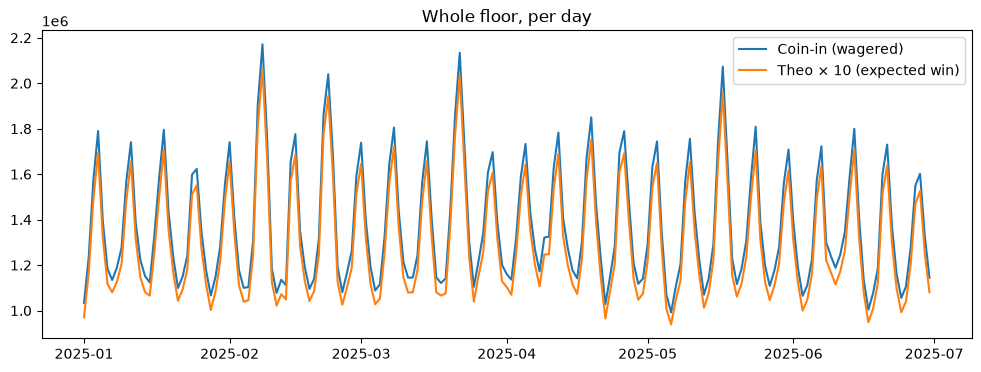

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

daily = pd.read_parquet("data/1_prepared_views/prepared_daily_view.parquet")
prop  = pd.read_parquet("data/1_prepared_views/property_day.parquet")
d = daily[daily["active"]]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(prop["gaming_date"], prop["coin_in_usd"], label="Coin-in (wagered)")
ax.plot(prop["gaming_date"], prop["theo_usd"] * 10, label="Theo × 10 (expected win)")
ax.set_title("Whole floor, per day")
ax.legend()
plt.show()

- **Spike 1:** Super Bowl weekend (Feb 7–9)
- **Spike 2:** Gilded Ace Winter Tournament (Feb 21–23)
- **Spike 3:** College basketball tournament opening rounds (Mar 20–22)
- **Spike 4:** EDC Las Vegas festival weekend (May 16–18)

**What the overview shows.** Play follows a strong weekly rhythm (weekends about 70% busier than weekdays) with no long-term decline. The four big spikes match events, which are analysed under Q2. Theo (expected win) tracks coin-in at about 9.5%, which is the floor's average designed hold.

---
## 2. Q1: Which machines are truly underperforming?

We test each explanation in turn:
- **Exposure:** was the machine on the floor all six months?
- **Availability:** was it broken?
- **Luck:** is actual win far from theo, beyond normal randomness?
- **Location vs game vs machine:** regression with zone, bank, game and day effects
- **Natural experiments:** machines that were replaced or moved

### 2.1 Actual vs expected win per machine

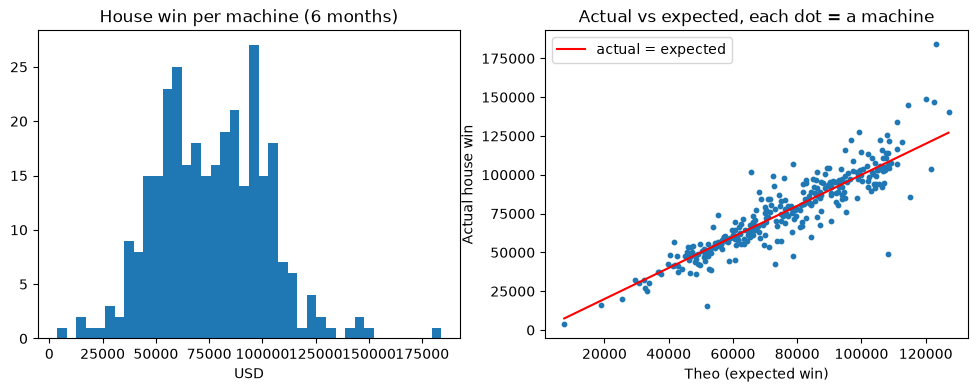

In [21]:
m = d.groupby("machine_id")[["house_win_usd", "theo_usd", "available_hours"]].sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(m["house_win_usd"], bins=40)
axes[0].set_title("House win per machine (6 months)")
axes[0].set_xlabel("USD")

axes[1].scatter(m["theo_usd"], m["house_win_usd"], s=10)
lim = [m["theo_usd"].min(), m["theo_usd"].max()]
axes[1].plot(lim, lim, color="red", label="actual = expected")
axes[1].set_xlabel("Theo (expected win)")
axes[1].set_ylabel("Actual house win")
axes[1].set_title("Actual vs expected, each dot = a machine")
axes[1].legend()
plt.show()

### 2.2 The two humps: Back Forty and four low-earning games

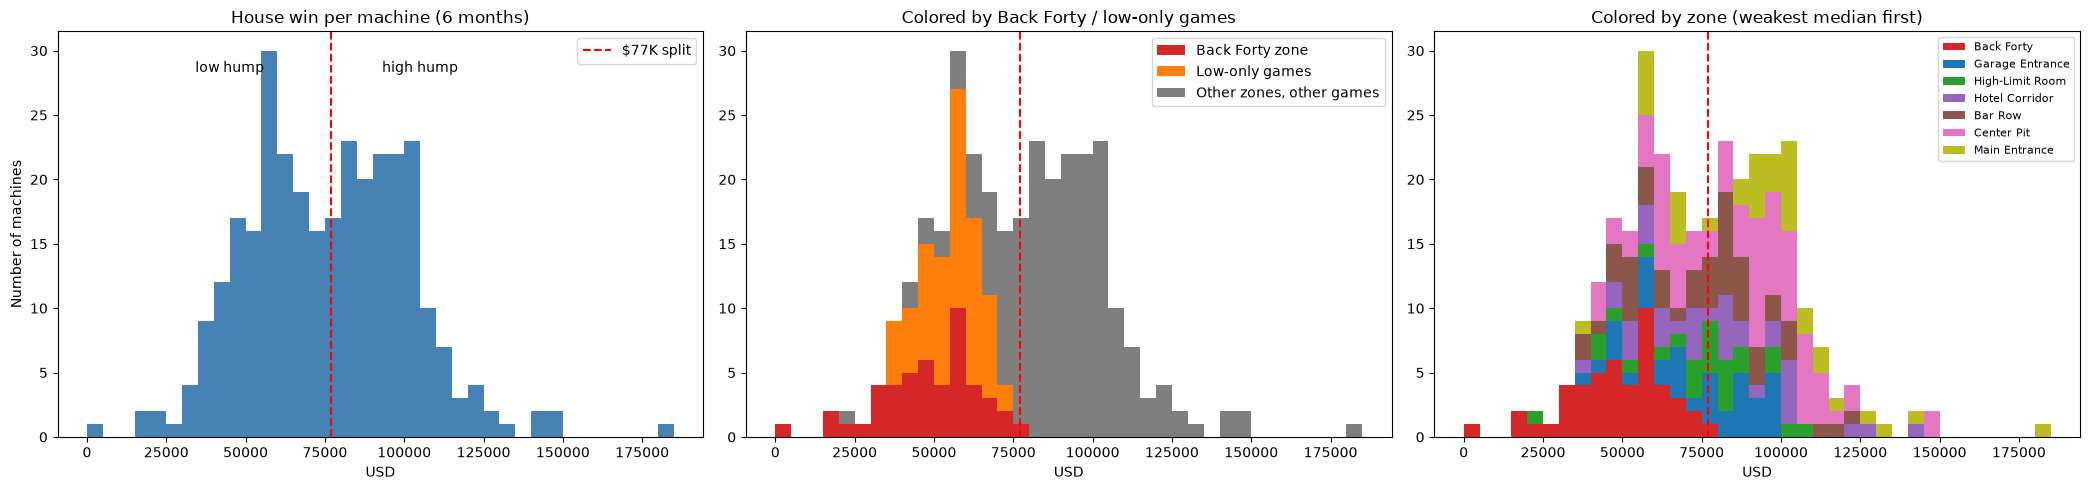

category
Other zones, other games    193
Low-only games               69
Back Forty zone              48
Name: count, dtype: int64


In [22]:
import matplotlib.pyplot as plt

daily = load("data/1_prepared_views/prepared_daily_view.parquet")
d = daily[daily["active"]]

m = d.groupby("machine_id").agg(
    house_win=("house_win_usd", "sum"),
    zone=("zone_name", "last"),
    theme=("theme", "first"),
)

low_games = ["Aurora Link", "Comet Cash", "Lucky Lanterns", "Royal Draw"]
m["category"] = "Other zones, other games"
m.loc[m["theme"].isin(low_games), "category"] = "Low-only games"
m.loc[m["zone"] == "Back Forty", "category"] = "Back Forty zone"

bins = range(0, 190_000, 5_000)
fig, axes = plt.subplots(1, 3, figsize=(21, 5))

# 1) Original histogram with the split line
axes[0].hist(m["house_win"], bins=bins, color="steelblue")
axes[0].axvline(77_000, color="red", linestyle="--", label="$77K split")
axes[0].text(45_000, axes[0].get_ylim()[1] * 0.9, "low hump", ha="center")
axes[0].text(105_000, axes[0].get_ylim()[1] * 0.9, "high hump", ha="center")
axes[0].set_title("House win per machine (6 months)")
axes[0].set_xlabel("USD")
axes[0].set_ylabel("Number of machines")
axes[0].legend()

# 2) Colored by Back Forty / low-only games / everything else
groups = ["Back Forty zone", "Low-only games", "Other zones, other games"]
colors = ["tab:red", "tab:orange", "tab:gray"]
axes[1].hist([m.loc[m["category"] == g, "house_win"] for g in groups],
             bins=bins, stacked=True, color=colors, label=groups)
axes[1].axvline(77_000, color="red", linestyle="--")
axes[1].set_title("Colored by Back Forty / low-only games")
axes[1].set_xlabel("USD")
axes[1].legend()

# 3) Colored by every zone, ordered from weakest to strongest median
zone_order = m.groupby("zone")["house_win"].median().sort_values().index
other_colors = ["tab:blue", "tab:green", "tab:purple", "tab:brown", "tab:pink", "tab:olive", "tab:cyan"]
zone_colors, i = {}, 0
for z in zone_order:
    if z == "Back Forty":
        zone_colors[z] = "tab:red"
    else:
        zone_colors[z] = other_colors[i]
        i += 1

axes[2].hist([m.loc[m["zone"] == z, "house_win"] for z in zone_order],
             bins=bins, stacked=True, label=zone_order,
             color=[zone_colors[z] for z in zone_order])
axes[2].axvline(77_000, color="red", linestyle="--")
axes[2].set_title("Colored by zone (weakest median first)")
axes[2].set_xlabel("USD")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

print(m["category"].value_counts())

### 2.3 Demand by zone × game (coin-in per working hour)

          theme  configured_rtp volatility_class  min_bet_cents  max_bet_cents
     Comet Cash            0.92             high             25            100
 Lucky Lanterns            0.92              low             25            100
    Neon Nights            0.88             high             40            200
Prairie Thunder            0.89           medium             40            200
    Desert Gold            0.90           medium             50            200
 Classic Sevens            0.93              low            100            300
    Aurora Link            0.91           medium             50            400
 Jackpot Summit            0.88        very_high            100            500
     Royal Draw            0.95              low             25            500
 Platinum Reels            0.90             high            500           2500 



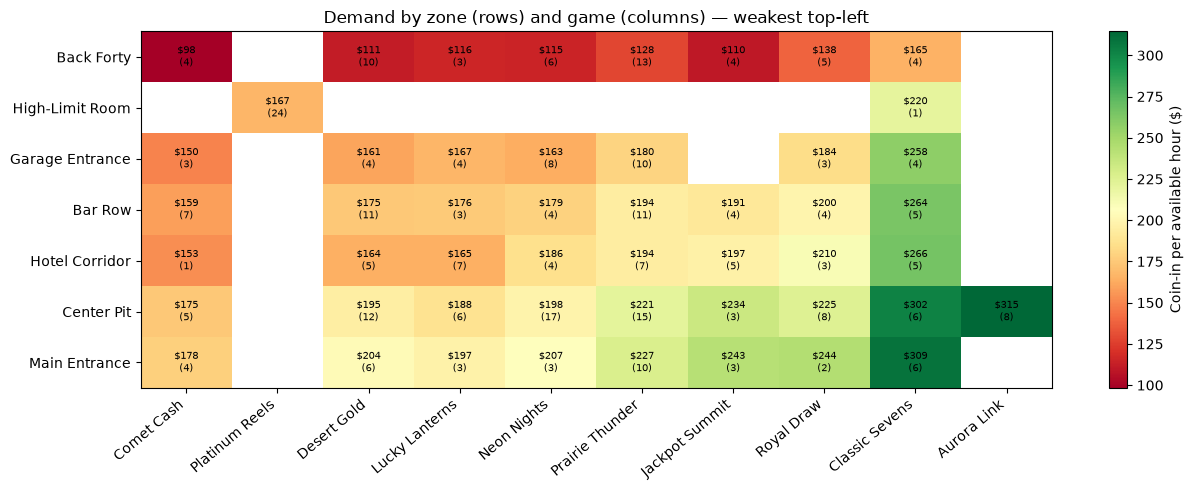

In [23]:
import matplotlib.pyplot as plt

daily = load("data/1_prepared_views/prepared_daily_view.parquet")
gm    = load("data/2_machine_decision/game_math.parquet")
d = daily[daily["active"]]

# 1) Game settings: are the low-only games just smaller-bet games?
print(gm[["theme", "configured_rtp", "volatility_class", "min_bet_cents", "max_bet_cents"]]
        .sort_values("max_bet_cents").to_string(index=False), "\n")

# 2) Fair demand measure: coin-in per available hour, for each zone x game
zg = d.groupby(["zone_name", "theme"]).agg(coin=("coin_in_usd", "sum"),
                                           hrs=("available_hours", "sum"),
                                           machines=("machine_id", "nunique"))
zg["rate"] = zg["coin"] / zg["hrs"]
rate = zg["rate"].unstack()
count = zg["machines"].unstack()

# Order zones and games from weakest to strongest
zone_rank = d.groupby("zone_name").apply(lambda g: g["coin_in_usd"].sum() / g["available_hours"].sum()).sort_values()
game_rank = d.groupby("theme").apply(lambda g: g["coin_in_usd"].sum() / g["available_hours"].sum()).sort_values()
rate = rate.loc[zone_rank.index, game_rank.index]
count = count.loc[zone_rank.index, game_rank.index]

# 3) Heatmap: each cell = $ wagered per available hour; number = machines in that cell
fig, ax = plt.subplots(figsize=(13, 5))
im = ax.imshow(rate, cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(len(rate.columns)), rate.columns, rotation=40, ha="right")
ax.set_yticks(range(len(rate.index)), rate.index)
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        if pd.notna(rate.iat[i, j]):
            ax.text(j, i, f"${rate.iat[i, j]:,.0f}\n({int(count.iat[i, j])})",
                    ha="center", va="center", fontsize=7)
plt.colorbar(im, label="Coin-in per available hour ($)")
ax.set_title("Demand by zone (rows) and game (columns) — weakest top-left")
plt.tight_layout()
plt.show()

### 2.4 Designed vs actual hold, by game

In [24]:
g = d.groupby("theme").agg(
    machines=("machine_id", "nunique"),
    coin_in=("coin_in_usd", "sum"),
    house_win=("house_win_usd", "sum"),
    theo=("theo_usd", "sum"),
    rtp=("configured_rtp", "mean"),
    volatility=("volatility_class", "first"),
)
g["actual_hold"]   = g["house_win"] / g["coin_in"]
g["designed_hold"] = g["theo"] / g["coin_in"]          # = 1 - RTP
g["gap_pts"]       = (g["actual_hold"] - g["designed_hold"]) * 100
g["win_per_machine"] = g["house_win"] / g["machines"]

print(g.sort_values("gap_pts")[["machines", "rtp", "volatility", "designed_hold",
                                "actual_hold", "gap_pts", "win_per_machine"]].round(3))

                 machines   rtp volatility  designed_hold  actual_hold  \
theme                                                                    
Comet Cash             24  0.92       high           0.08        0.077   
Royal Draw             25  0.95        low           0.05        0.049   
Desert Gold            48  0.90     medium           0.10        0.099   
Lucky Lanterns         24  0.92        low           0.08        0.080   
Prairie Thunder        66  0.89     medium           0.11        0.110   
Classic Sevens         31  0.93        low           0.07        0.070   
Aurora Link             8  0.91     medium           0.09        0.091   
Neon Nights            42  0.88       high           0.12        0.121   
Jackpot Summit         18  0.88  very_high           0.12        0.124   
Platinum Reels         24  0.90       high           0.10        0.106   

                 gap_pts  win_per_machine  
theme                                      
Comet Cash        -0.31

### 2.5 Exposure and availability: why Aurora Link looks low

In [48]:
machines = load("data/2_machine_decision/machines.parquet")
cal = load("data/2_machine_decision/calendar_day.parquet")

dd = d.merge(cal[["gaming_date", "scheduled_seconds"]], on="gaming_date")
ex = dd.groupby("theme").agg(
    machines=("machine_id", "nunique"),
    days_per_machine=("gaming_date", "count"),
    avail_hrs=("available_hours", "sum"),
    sched_hrs=("scheduled_seconds", lambda s: s.sum() / 3600),
    faults=("faults_opened", "sum"),
)
ex["days_per_machine"] = ex["days_per_machine"] / ex["machines"]
ex["availability"] = ex["avail_hrs"] / ex["sched_hrs"]
ex["faults_per_machine"] = ex["faults"] / ex["machines"]
print(ex[["machines", "days_per_machine", "availability", "faults_per_machine"]].round(3), "\n")

# Aurora Link machines individually
al = machines[machines["theme"] == "Aurora Link"]
print(al[["machine_id", "manufacturer", "install_date", "retire_date"]].to_string(index=False))

                 machines  days_per_machine  availability  faults_per_machine
theme                                                                        
Aurora Link             8            99.000         0.995               1.750
Classic Sevens         31           179.226         0.997               3.677
Comet Cash             24           181.000         0.995               5.083
Desert Gold            48           181.000         0.996               3.979
Jackpot Summit         18           181.000         0.997               3.167
Lucky Lanterns         24           181.000         0.995               5.125
Neon Nights            42           181.000         0.996               4.000
Platinum Reels         24           175.750         0.999               0.625
Prairie Thunder        66           181.000         0.996               4.288
Royal Draw             25           173.760         0.995               4.800 

machine_id manufacturer install_date retire_date
    M-2642   

### 2.6 Replacements, additions and retirements

In [26]:
placements = load("data/2_machine_decision/placements.parquet")

# Machines that left the floor during the period
retired = machines[machines["retire_date"].notna()]
print("Retired machines:")
print(retired[["machine_id", "manufacturer", "theme", "install_date", "retire_date"]].to_string(index=False), "\n")

# Which slots the Aurora Link machines went into, and who was there before
al_ids = machines.loc[machines["theme"] == "Aurora Link", "machine_id"]
al_slots = placements.loc[placements["machine_id"].isin(al_ids), "location_id"].unique()
history = placements[placements["location_id"].isin(al_slots)] \
            .merge(machines[["machine_id", "theme"]], on="machine_id") \
            .sort_values(["location_id", "effective_from_utc"])
print("History of the Aurora Link slots:")
print(history[["location_id", "machine_id", "theme", "effective_from_utc", "effective_to_utc"]].to_string(index=False))

Retired machines:
machine_id manufacturer          theme install_date retire_date
    M-1118    Ridgeline Platinum Reels   2019-02-16  2025-02-25
    M-1120    Ridgeline     Royal Draw   2018-02-16  2025-05-13 

History of the Aurora Link slots:
location_id machine_id       theme  effective_from_utc effective_to_utc
     L-51-1     M-2642 Aurora Link 2025-03-24 13:00:00              NaT
     L-51-2     M-8743 Aurora Link 2025-03-24 13:00:00              NaT
     L-51-3     M-8057 Aurora Link 2025-03-24 13:00:00              NaT
     L-51-4     M-2799 Aurora Link 2025-03-24 13:00:00              NaT
     L-51-5     M-7943 Aurora Link 2025-03-24 13:00:00              NaT
     L-51-6     M-3101 Aurora Link 2025-03-24 13:00:00              NaT
     L-51-7     M-7756 Aurora Link 2025-03-24 13:00:00              NaT
     L-51-8     M-7487 Aurora Link 2025-03-24 13:00:00              NaT


In [27]:
# 1) Every machine installed during the six months
new = machines[machines["install_date"] >= pd.Timestamp("2025-01-01").date()]
print("Installed during the period:")
print(new[["machine_id", "manufacturer", "theme", "install_date"]].to_string(index=False), "\n")

# 2) Did the new Aurora Link bank pull play from other Center Pit machines?
cp = d[(d["zone_name"] == "Center Pit") & (~d["theme"].eq("Aurora Link"))].copy()
cp["period"] = (cp["gaming_date"] >= pd.Timestamp("2025-03-24").date()).map({False: "before Mar 24", True: "after Mar 24"})
rest = d[d["zone_name"] != "Center Pit"].copy()
rest["period"] = (rest["gaming_date"] >= pd.Timestamp("2025-03-24").date()).map({False: "before Mar 24", True: "after Mar 24"})

def rate(x):
    return x.groupby("period").apply(lambda g: g["coin_in_usd"].sum() / g["available_hours"].sum())

out = pd.DataFrame({"Center Pit (other games)": rate(cp), "Rest of floor": rate(rest)})
out.loc["change"] = out.loc["after Mar 24"] / out.loc["before Mar 24"] - 1
print("Coin-in per available hour:")
print(out.round(3))

Installed during the period:
machine_id manufacturer          theme install_date
    M-1532    Northwind Classic Sevens   2025-02-25
    M-2642      Halcyon    Aurora Link   2025-03-24
    M-2799      Halcyon    Aurora Link   2025-03-24
    M-3101      Halcyon    Aurora Link   2025-03-24
    M-5076      Halcyon     Royal Draw   2025-05-13
    M-7487      Halcyon    Aurora Link   2025-03-24
    M-7756      Halcyon    Aurora Link   2025-03-24
    M-7943      Halcyon    Aurora Link   2025-03-24
    M-8057      Halcyon    Aurora Link   2025-03-24
    M-8743      Halcyon    Aurora Link   2025-03-24 



Coin-in per available hour:
               Center Pit (other games)  Rest of floor
period                                                
after Mar 24                    207.743        173.265
before Mar 24                   219.396        186.024
change                           -0.053         -0.069


### 2.7 Natural experiment 1: the two machine replacements

In [28]:
cases = [("M-1118", "M-1532", "2025-02-25"),   # Platinum Reels -> Classic Sevens
         ("M-1120", "M-5076", "2025-05-13")]   # old Royal Draw -> new Royal Draw

for old, new_id, swap in cases:
    swap = pd.Timestamp(swap).date()
    slot = d.loc[d["machine_id"] == new_id, "location_id"].iloc[0]
    zone = d.loc[d["machine_id"] == new_id, "zone_name"].iloc[0]

    s = d[d["location_id"] == slot]                               # the slot itself
    z = d[(d["zone_name"] == zone) & (d["location_id"] != slot)]  # rest of its zone = control

    def per_hr(x, col):
        b = x[x["gaming_date"] < swap]
        a = x[x["gaming_date"] >= swap]
        return (b[col].sum() / b["available_hours"].sum(),
                a[col].sum() / a["available_hours"].sum())

    sb, sa = per_hr(s, "coin_in_usd")
    zb, za = per_hr(z, "coin_in_usd")
    tb, ta = per_hr(s, "theo_usd")

    print(f"\n{old} -> {new_id}  (slot {slot}, {zone}, swap {swap})")
    print(f"  Slot coin-in/hr:  before ${sb:,.0f}  after ${sa:,.0f}  change {sa/sb-1:+.0%}")
    print(f"  Zone coin-in/hr:  before ${zb:,.0f}  after ${za:,.0f}  change {za/zb-1:+.0%}   (control)")
    print(f"  Slot theo/hr:     before ${tb:,.2f}  after ${ta:,.2f}  change {ta/tb-1:+.0%}")


M-1118 -> M-1532  (slot L-27-3, High-Limit Room, swap 2025-02-25)
  Slot coin-in/hr:  before $193  after $220  change +14%
  Zone coin-in/hr:  before $175  after $163  change -7%   (control)
  Slot theo/hr:     before $19.28  after $15.39  change -20%

M-1120 -> M-5076  (slot L-38-5, Back Forty, swap 2025-05-13)
  Slot coin-in/hr:  before $120  after $128  change +6%
  Zone coin-in/hr:  before $122  after $123  change +1%   (control)
  Slot theo/hr:     before $6.00  after $6.39  change +6%


Swap 1 (Platinum Reels → Classic Sevens): play +14% vs the zone's −7%, but **theo/hr −20%** because the new game keeps 7% instead of 10%.
Swap 2 (old → new Royal Draw in Back Forty): about +5% vs the zone, only **+$0.39 theo/hr**, which doesn't pay for a replacement.

### 2.8 Luck test: is any single machine paying out abnormally?

In [29]:
md = load("data/2_machine_decision/machine_day.parquet")
gm = load("data/2_machine_decision/game_math.parquet")

# How much luck is normal for each machine (from bet sizes and game swinginess)
mdx = md[md["active"]].merge(gm[["config_id", "payout_multiplier_variance"]], on="config_id")
mdx["luck_var"] = mdx["sum_bet_squared"].astype(float) * mdx["payout_multiplier_variance"]
luck_sd = (mdx.groupby("machine_id")["luck_var"].sum() ** 0.5 / 100).rename("luck_sd")

# Actual vs expected per machine
lk = d.groupby("machine_id").agg(
    house_win=("house_win_usd", "sum"),
    theo=("theo_usd", "sum"),
    coin_in=("coin_in_usd", "sum"),
    rtp=("configured_rtp", "first"),
    theme=("theme", "first"),
    zone=("zone_name", "last"),
    volatility=("volatility_class", "first"),
).join(luck_sd)

lk["luck"]          = lk["house_win"] - lk["theo"]
lk["z"]             = lk["luck"] / lk["luck_sd"]
lk["actual_hold"]   = lk["house_win"] / lk["coin_in"]
lk["designed_hold"] = 1 - lk["rtp"]

# Check the luck math works: std should be near 1
print("z across all machines: mean", round(lk["z"].mean(), 2), " std", round(lk["z"].std(), 2), "\n")

cols = ["theme", "zone", "volatility", "designed_hold", "actual_hold", "luck", "z"]
print("Most unusual LOW results (possible leaks):")
print(lk.nsmallest(8, "z")[cols].round(3), "\n")
print("Most unusual HIGH results (very lucky):")
print(lk.nlargest(5, "z")[cols].round(3))

z across all machines: mean -0.07  std 1.09 

Most unusual LOW results (possible leaks):
                      theme             zone volatility  designed_hold  \
machine_id                                                               
M-1158          Desert Gold       Back Forty     medium           0.10   
M-1054      Prairie Thunder  Garage Entrance     medium           0.11   
M-1210           Royal Draw    Main Entrance        low           0.05   
M-1010          Desert Gold       Center Pit     medium           0.10   
M-1181           Comet Cash       Back Forty       high           0.08   
M-1201      Prairie Thunder   Hotel Corridor     medium           0.11   
M-1288       Jackpot Summit   Hotel Corridor  very_high           0.12   
M-1300           Comet Cash    Main Entrance       high           0.08   

            actual_hold       luck      z  
machine_id                                 
M-1158            0.030 -36164.750 -4.570  
M-1054            0.090 -14528.384 -2.

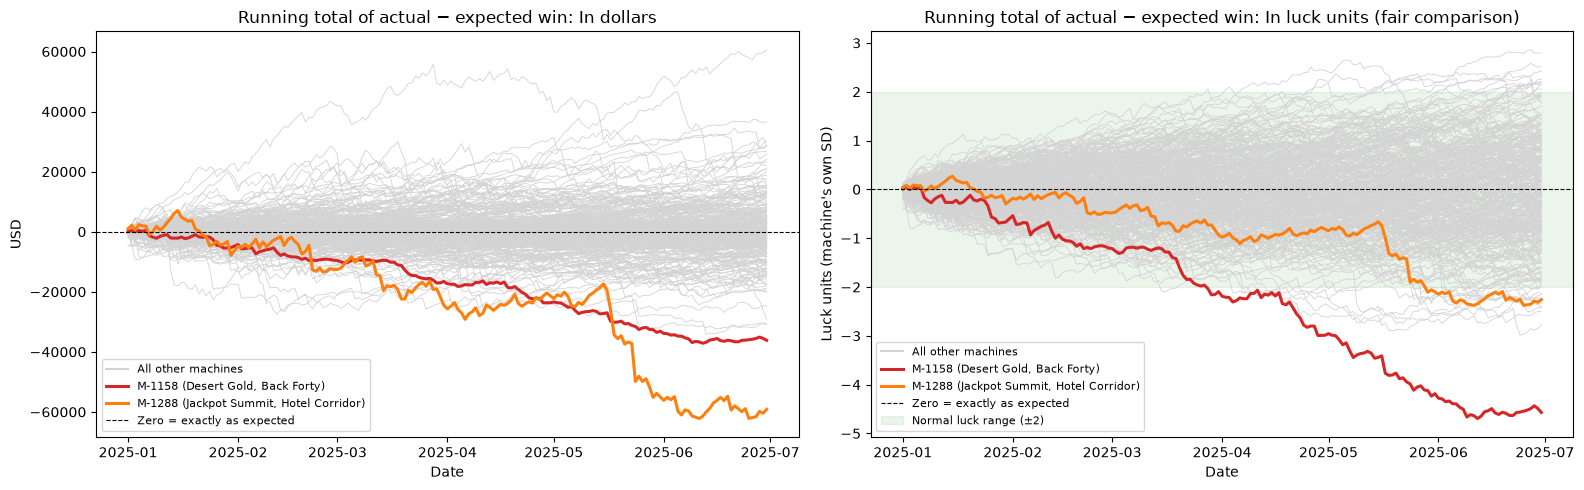

In [30]:
import matplotlib.pyplot as plt

# Running total of actual − expected for every machine
dd = d.sort_values("gaming_date").copy()
dd["luck"] = dd["house_win_usd"] - dd["theo_usd"]
cum = dd.pivot_table(index="gaming_date", columns="machine_id", values="luck", aggfunc="sum").fillna(0).cumsum()
cum_z = cum / lk["luck_sd"]            # in units of each machine's normal luck (uses lk from the leak test)

highlight = {"M-1158": "tab:red",      # leak candidate (z -4.6)
             "M-1288": "tab:orange"}   # biggest dollar loss, but normal for its volatility (z -2.3)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, data, ylabel, title in [
        (axes[0], cum,   "USD",                          "In dollars"),
        (axes[1], cum_z, "Luck units (machine's own SD)", "In luck units (fair comparison)")]:
    ax.plot(data.index, data, color="lightgray", linewidth=0.6)
    ax.plot([], [], color="lightgray", label="All other machines")
    for mid, col in highlight.items():
        ax.plot(data.index, data[mid], color=col, linewidth=2.2,
                label=f"{mid} ({lk.loc[mid, 'theme']}, {lk.loc[mid, 'zone']})")
    ax.axhline(0, color="black", linestyle="--", linewidth=0.8, label="Zero = exactly as expected")
    ax.set_title(f"Running total of actual − expected win: {title}")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Date")

# Normal-luck band on the fair chart
axes[1].axhspan(-2, 2, color="green", alpha=0.08, label="Normal luck range (±2)")

for ax in axes:
    ax.legend(loc="lower left", fontsize=8)

plt.tight_layout()
plt.show()

The luck model is calibrated: z across all machines has mean −0.07 and std 1.09, close to the ideal 0 and 1.
**M-1158** (Desert Gold, Back Forty) kept 3% instead of 10% (z = −4.6, about 2 in a million by luck) and drifts down steadily. That makes it a **lead to inspect, not proof of wrongdoing**. M-1288 lost the most dollars ($59K) but is within normal luck for a very-high-volatility game.

### 2.9 Regression: location vs game vs machine
Target: log of coin-in per working hour, one row per active machine-day, weighted by working hours, with a term for every calendar day (so weekends and events don't bias the comparison). Needs `statsmodels`.

Rows: 55,075   R²: 0.521


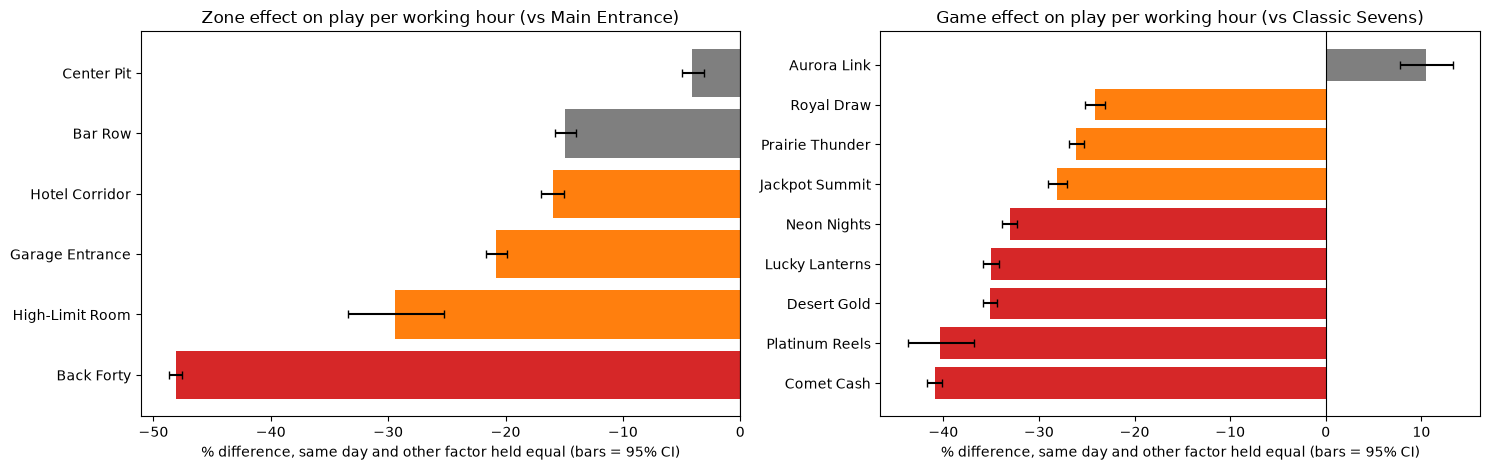


Zone effects:
 Back Forty         -48.1%
High-Limit Room    -29.4%
Garage Entrance    -20.8%
Hotel Corridor     -16.0%
Bar Row            -14.9%
Center Pit          -4.1%
Name: effect, dtype: str

Game effects:
 Comet Cash         -40.9%
Platinum Reels     -40.4%
Desert Gold        -35.1%
Lucky Lanterns     -35.0%
Neon Nights        -33.0%
Jackpot Summit     -28.1%
Prairie Thunder    -26.1%
Royal Draw         -24.1%
Aurora Link         10.5%
Name: effect, dtype: str


In [31]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
warnings.filterwarnings("ignore", message=".*rank-deficient.*")
 
daily = load("data/1_prepared_views/prepared_daily_view.parquet")
r = daily[daily["active"] & (daily["available_hours"] > 0) & (daily["coin_in_usd"] > 0)].copy()
r["y"] = np.log(r["coin_in_usd"] / r["available_hours"])     # log of $ wagered per working hour
r["date"] = r["gaming_date"].astype(str)
 
# Model 1: zone + game + each calendar day. Weighted by working hours.
m1 = smf.wls("y ~ C(zone_name, Treatment('Main Entrance')) + C(theme, Treatment('Classic Sevens')) + C(date)",
             data=r, weights=r["available_hours"]).fit()
print(f"Rows: {len(r):,}   R²: {m1.rsquared:.3f}")
 
def effects(prefix, label):
    p, ci = m1.params.filter(like=prefix), m1.conf_int().filter(like=prefix, axis=0)
    out = pd.DataFrame({"effect": np.exp(p) - 1, "low": np.exp(ci[0]) - 1, "high": np.exp(ci[1]) - 1})
    out.index = [i.split("[T.")[1].rstrip("]") for i in out.index]
    return out.sort_values("effect")
 
zone_eff = effects("zone_name", "zone")
game_eff = effects("theme", "game")
 
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, eff, ref, title in [(axes[0], zone_eff, "Main Entrance", "Zone effect"),
                            (axes[1], game_eff, "Classic Sevens", "Game effect")]:
    colors = ["tab:red" if v < -0.3 else "tab:orange" if v < -0.15 else "tab:gray" for v in eff["effect"]]
    ax.barh(eff.index, eff["effect"] * 100, color=colors,
            xerr=[(eff["effect"] - eff["low"]) * 100, (eff["high"] - eff["effect"]) * 100], capsize=3)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{title} on play per working hour (vs {ref})")
    ax.set_xlabel("% difference, same day and other factor held equal (bars = 95% CI)")
plt.tight_layout()
plt.show()
 
print("\nZone effects:\n", (zone_eff["effect"] * 100).round(1).astype(str) + "%")
print("\nGame effects:\n", (game_eff["effect"] * 100).round(1).astype(str) + "%")
 

### 2.10 Effects vs the floor average: occupancy vs bet intensity

Zone effect vs floor average (%):
                  Coin-in / hr  Theo / hr  Occupancy  Coin-in per occupied hr
Back Forty              -35.8      -35.8      -35.1                     -1.1
High-Limit Room         -12.7      -12.7      -14.5                      2.2
Garage Entrance          -1.9       -1.9        2.5                     -4.3
Hotel Corridor            4.0        4.0        0.6                      3.4
Bar Row                   5.3        5.3        8.5                     -2.9
Center Pit               18.8       18.8       18.1                      0.5
Main Entrance            23.8       23.8       19.1                      3.9

Game effect vs floor average (%):
                  Coin-in / hr  Theo / hr  Occupancy  Coin-in per occupied hr
Comet Cash              -16.6      -28.4       26.6                    -34.1
Platinum Reels          -15.9       -9.7      -84.4                    439.3
Desert Gold              -8.5       -1.8        8.3                    -15.5
Lucky

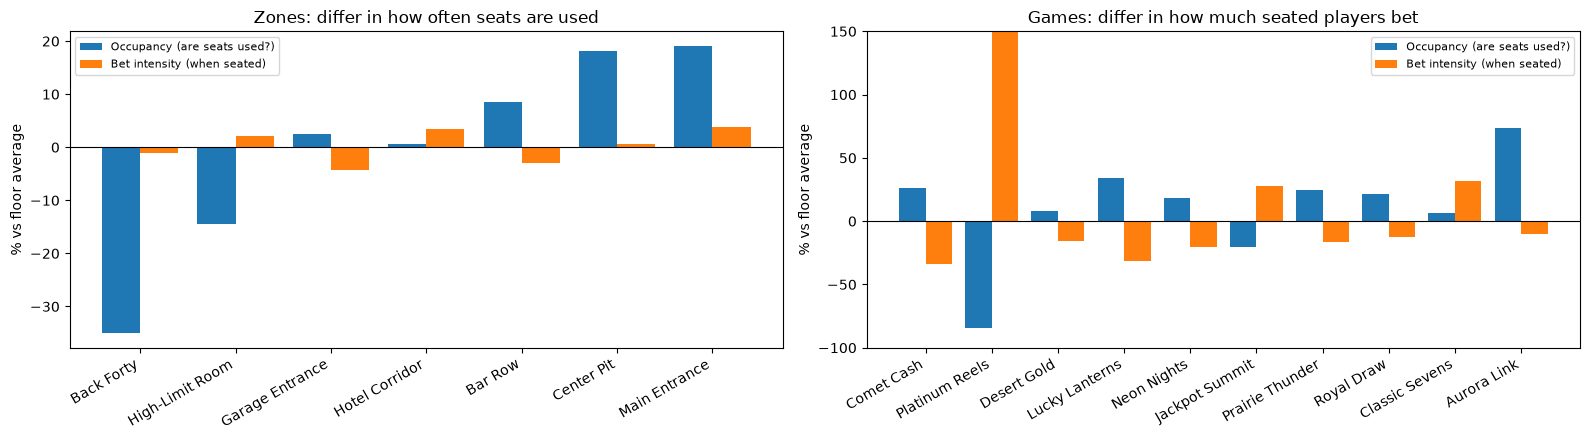

In [32]:
# Zone and game effects vs FLOOR AVERAGE, on four normalized targets
rr = r[r["occupied_hours"] > 0].copy()
rr["y_coin"] = np.log(rr["coin_in_usd"] / rr["available_hours"])     # $ wagered per working hour
rr["y_theo"] = np.log(rr["theo_usd"] / rr["available_hours"])        # expected win per working hour
rr["y_occ"]  = np.log(rr["occupied_hours"] / rr["available_hours"])  # share of working time in use
rr["y_rate"] = np.log(rr["coin_in_usd"] / rr["occupied_hours"])      # $ wagered per hour someone is playing

def normalized_effects(factor):
    share = rr.groupby(factor)["available_hours"].sum()
    share = share / share.sum()
    res = {}
    for col, label in [("y_coin", "Coin-in / hr"), ("y_theo", "Theo / hr"),
                       ("y_occ", "Occupancy"), ("y_rate", "Coin-in per occupied hr")]:
        m = smf.wls(f"{col} ~ C(zone_name) + C(theme) + C(date)", data=rr, weights=rr["available_hours"]).fit()
        p = m.params.filter(like=factor)
        p.index = [i.split("[T.")[1].rstrip("]") for i in p.index]
        base = [z for z in share.index if z not in p.index][0]
        p[base] = 0.0
        res[label] = (np.exp(p - (p * share).sum()) - 1) * 100
    return pd.DataFrame(res).sort_values("Coin-in / hr")

zone_norm = normalized_effects("zone_name")
game_norm = normalized_effects("theme")
print("Zone effect vs floor average (%):\n", zone_norm.round(1))
print("\nGame effect vs floor average (%):\n", game_norm.round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, tbl, title in [(axes[0], zone_norm, "Zones: differ in how often seats are used"),
                       (axes[1], game_norm, "Games: differ in how much seated players bet")]:
    x = np.arange(len(tbl))
    ax.bar(x - 0.2, tbl["Occupancy"], 0.4, label="Occupancy (are seats used?)", color="tab:blue")
    ax.bar(x + 0.2, tbl["Coin-in per occupied hr"], 0.4, label="Bet intensity (when seated)", color="tab:orange")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x, tbl.index, rotation=30, ha="right")
    ax.set_ylabel("% vs floor average")
    ax.set_title(title)
    ax.legend(fontsize=8)
axes[1].set_ylim(-100, 150)   # Platinum Reels bet intensity (+439%) runs off the top; its value is in the table
plt.tight_layout()
plt.show()

Play per hour = **occupancy** (are seats used?) × **bet intensity** (how much seated players wager per hour).
- **Zones differ in occupancy.** Back Forty seats are empty 35% more than average, while seated players bet about the same (−1%).
- **Games differ in bet size.** Comet Cash and Lucky Lanterns have *above-average* occupancy but low bets ($1 max), so they are low-stakes games, not unpopular ones. Platinum Reels is the reverse; it only appears in the High-Limit Room, so its effect describes high-limit play overall.

### 2.11 How much of the difference between machines each factor explains

Zone only      68.7% of between-machine differences explained
Game only      43.0% of between-machine differences explained
Zone + game    95.6% of between-machine differences explained
Bank + game    98.7% of between-machine differences explained
dtype: str


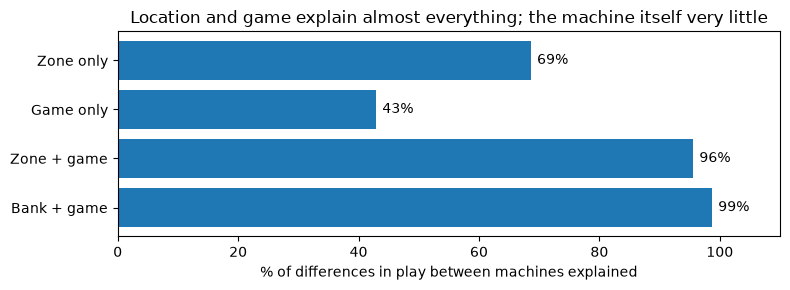

In [33]:
# How much of the difference BETWEEN machines does each factor explain?
day_only = smf.wls("y ~ C(date)", data=r, weights=r["available_hours"]).fit()
r["y_adj"] = day_only.resid                     # play level with day-to-day swings removed

mach = r.groupby("machine_id").apply(lambda g: pd.Series({
    "y": np.average(g["y_adj"], weights=g["available_hours"]),
    "zone": g["zone_name"].iloc[-1], "bank": g["bank_id"].iloc[-1], "theme": g["theme"].iloc[0]}))
mach["y"] = mach["y"].astype(float)

shares = pd.Series({name: smf.ols(f"y ~ {f}", data=mach).fit().rsquared for name, f in
          [("Zone only", "C(zone)"), ("Game only", "C(theme)"),
           ("Zone + game", "C(zone) + C(theme)"), ("Bank + game", "C(bank) + C(theme)")]})
print((shares * 100).round(1).astype(str) + "% of between-machine differences explained")

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(shares.index[::-1], shares.values[::-1] * 100, color="tab:blue")
for i, v in enumerate(shares.values[::-1]):
    ax.text(v * 100 + 1, i, f"{v:.0%}", va="center")
ax.set_xlim(0, 110)
ax.set_xlabel("% of differences in play between machines explained")
ax.set_title("Location and game explain almost everything; the machine itself very little")
plt.tight_layout()
plt.show()

### 2.12 Machine effects and the manager's bottom 10

Machine effects: Jan-Mar vs Apr-Jun correlation = 0.29  (1 = fully stable, 0 = noise)

Machines weaker than their own bank and game in BOTH halves:
                      zone            theme  machine_effect  jan_mar  apr_jun  \
machine_id                                                                      
M-1184          Back Forty   Jackpot Summit          -0.140   -0.166   -0.120   
M-1154          Back Forty   Jackpot Summit          -0.105   -0.088   -0.127   
M-1084      Hotel Corridor   Lucky Lanterns          -0.071   -0.084   -0.068   
M-1171             Bar Row  Prairie Thunder          -0.068   -0.065   -0.072   
M-1081       Main Entrance   Lucky Lanterns          -0.056   -0.076   -0.047   

                t  
machine_id         
M-1184     -4.469  
M-1154     -3.342  
M-1084     -4.523  
M-1171     -4.497  
M-1081     -3.854  

Manager's bottom 10:
                       zone           theme  house_win  days  machine_effect            main reason
machine_id            

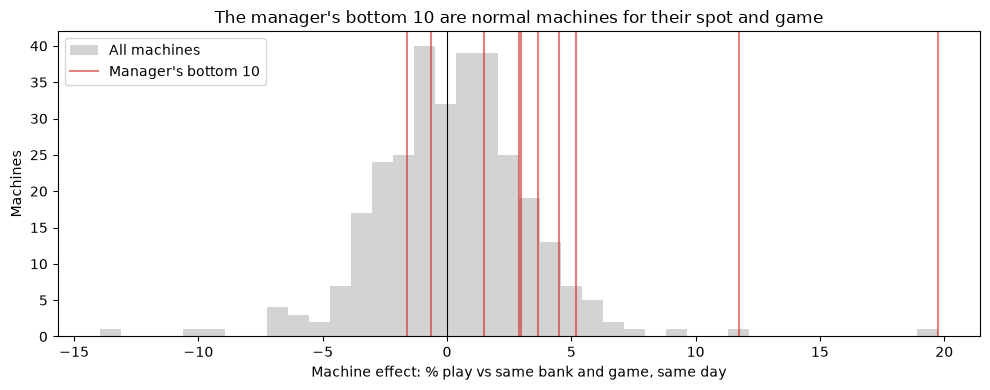

In [34]:
# Model 2: each machine compared with its own bank and game -> the "machine effect"
def machine_effects(data):
    m = smf.wls("y ~ C(bank_id) + C(theme) + C(date)", data=data, weights=data["available_hours"]).fit()
    g = data.assign(resid=m.resid).groupby("machine_id")
    eff = g.apply(lambda x: np.average(x["resid"], weights=x["available_hours"]))
    se = g["resid"].std() / np.sqrt(g.size())
    return pd.DataFrame({"machine_effect": np.exp(eff) - 1, "t": eff / se})

me = machine_effects(r)

# Stability check: are machine effects the same in Jan-Mar and Apr-Jun?
first  = machine_effects(r[r["date"] <  "2025-04-01"])["machine_effect"]
second = machine_effects(r[r["date"] >= "2025-04-01"])["machine_effect"]
both = pd.concat([first, second], axis=1, keys=["jan_mar", "apr_jun"]).dropna()
print(f"Machine effects: Jan-Mar vs Apr-Jun correlation = {both.corr().iloc[0, 1]:.2f}  (1 = fully stable, 0 = noise)")

weak = me[(me["machine_effect"] < -0.05) & (me["t"] < -3)].join(both)
weak = weak[(weak["jan_mar"] < -0.03) & (weak["apr_jun"] < -0.03)]      # weak in BOTH halves
info = daily[daily["active"]].groupby("machine_id").agg(zone=("zone_name", "last"), theme=("theme", "first"),
                                                       house_win=("house_win_usd", "sum"), days=("gaming_date", "count"))
print("\nMachines weaker than their own bank and game in BOTH halves:")
print(weak.join(info).sort_values("machine_effect")[["zone", "theme", "machine_effect", "jan_mar", "apr_jun", "t"]].round(3))

# The manager's bottom 10, explained
b10 = info.nsmallest(10, "house_win").join(me)
def reason(row):
    if row["days"] < 150:             return "Partial time on floor"
    if row["machine_effect"] < -0.05: return "Weak machine"
    if row["zone"] == "Back Forty":   return "Location (Back Forty)"
    return "Game / other"
b10["main reason"] = b10.apply(reason, axis=1)
print("\nManager's bottom 10:")
print(b10[["zone", "theme", "house_win", "days", "machine_effect", "main reason"]].round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(me["machine_effect"] * 100, bins=40, color="lightgray", label="All machines")
for i, (mid, v) in enumerate(b10["machine_effect"].items()):
    ax.axvline(v * 100, color="tab:red", alpha=0.6, label="Manager's bottom 10" if i == 0 else None)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Machine effect: % play vs same bank and game, same day")
ax.set_ylabel("Machines")
ax.set_title("The manager's bottom 10 are normal machines for their spot and game")
ax.legend()
plt.tight_layout()
plt.show()

Machine effects are only weakly stable between Jan–Mar and Apr–Jun (correlation ≈ 0.29), so most machine-to-machine differences are noise. Only machines weak in **both** halves are flagged.

### 2.13 When are machines played? PCA on 24-hour occupancy patterns (needs `scikit-learn`)

Share of variation explained by each component: [76.5  2.8  2.5  2.1] %

Average PC1 by zone (higher = play more concentrated in the evening):
zone_name
Center Pit        -0.40
Main Entrance     -0.31
Garage Entrance   -0.22
Bar Row           -0.21
Hotel Corridor    -0.03
Back Forty         0.45
High-Limit Room    1.60
Name: PC1, dtype: float64


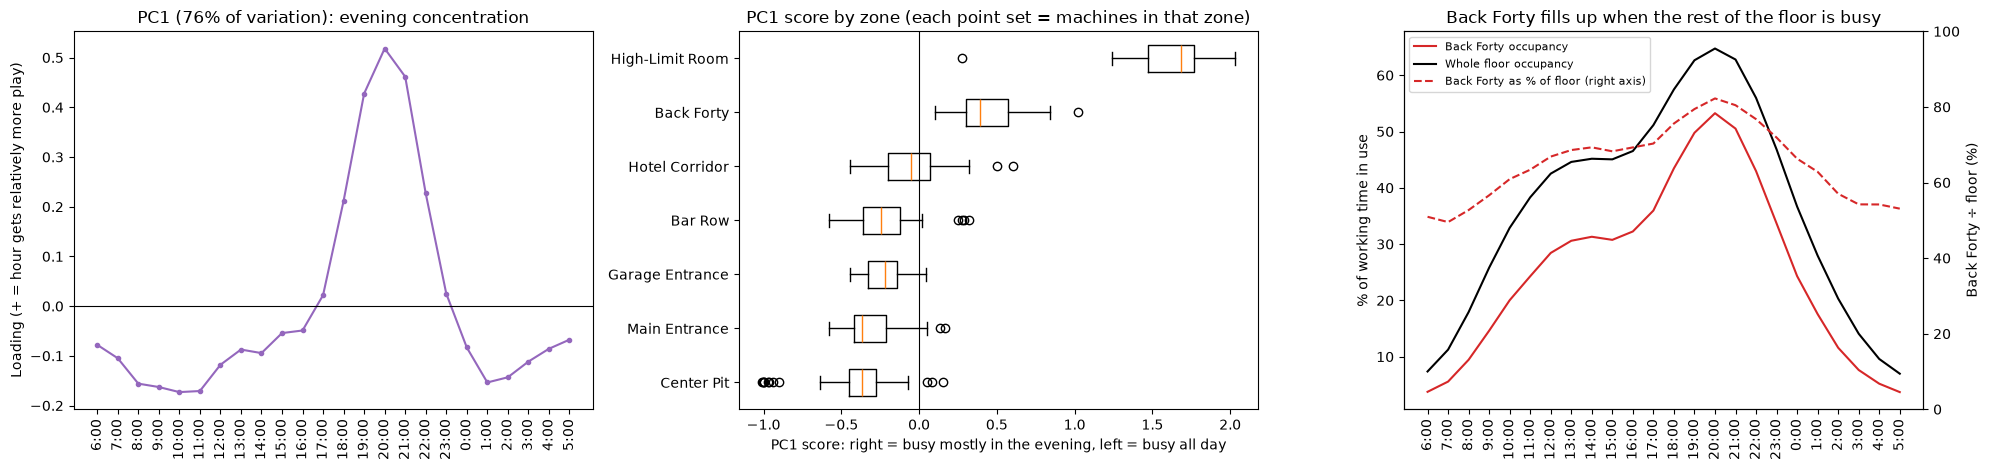


Back Forty occupancy as % of floor occupancy:
  6-9 a.m.: 52%   2-4 p.m.: 69%   7-9 p.m. peak: 81%   2-4 a.m.: 55%


In [35]:
# PCA on each machine's 24-hour occupancy pattern (needs scikit-learn)
from sklearn.decomposition import PCA

mh = pd.read_parquet("data/5_optional/machine_hour.parquet",
                     columns=["machine_id", "local_hour", "active", "available_seconds", "occupied_seconds"])
mh = mh[mh["active"] & (mh["available_seconds"] > 0)]

hours = list(range(6, 24)) + list(range(0, 6))            # gaming day order: 6 a.m. -> 5 a.m.
hr = mh.groupby(["machine_id", "local_hour"])[["occupied_seconds", "available_seconds"]].sum()
occ = (hr["occupied_seconds"] / hr["available_seconds"]).unstack()[hours]   # occupancy by hour, one row per machine
shape = occ.div(occ.mean(axis=1), axis=0)                 # SHAPE only: 1.0 = that machine's own average hour

pca = PCA().fit(shape)
print("Share of variation explained by each component:", (pca.explained_variance_ratio_[:4] * 100).round(1), "%")

zones = daily[daily["active"]].groupby("machine_id")["zone_name"].last()
scores = pd.DataFrame(pca.transform(shape)[:, :2], index=shape.index, columns=["PC1", "PC2"]).join(zones)
print("\nAverage PC1 by zone (higher = play more concentrated in the evening):")
print(scores.groupby("zone_name")["PC1"].mean().sort_values().round(2))

# Back Forty occupancy relative to the whole floor, hour by hour
mh = mh.join(zones, on="machine_id")
zh = mh.groupby(["zone_name", "local_hour"])[["occupied_seconds", "available_seconds"]].sum()
zone_occ = (zh["occupied_seconds"] / zh["available_seconds"]).unstack(0).reindex(hours)
fh = mh.groupby("local_hour")[["occupied_seconds", "available_seconds"]].sum().reindex(hours)
floor_occ = fh["occupied_seconds"] / fh["available_seconds"]
bf_ratio = zone_occ["Back Forty"] / floor_occ

labels = [f"{h}:00" for h in hours]
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))

axes[0].plot(labels, pca.components_[0], color="tab:purple", marker="o", markersize=3)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_title(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variation): evening concentration")
axes[0].set_ylabel("Loading (+ = hour gets relatively more play)")
axes[0].tick_params(axis="x", rotation=90)

order = scores.groupby("zone_name")["PC1"].mean().sort_values().index
box_data = [scores.loc[scores["zone_name"] == z, "PC1"] for z in order]
try:
    axes[1].boxplot(box_data, orientation="horizontal")   # matplotlib 3.10+
except TypeError:
    axes[1].boxplot(box_data, vert=False)                 # older matplotlib
axes[1].set_yticks(range(1, len(order) + 1), order)
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_title("PC1 score by zone (each point set = machines in that zone)")
axes[1].set_xlabel("PC1 score: right = busy mostly in the evening, left = busy all day")

axes[2].plot(labels, zone_occ["Back Forty"] * 100, color="tab:red", label="Back Forty occupancy")
axes[2].plot(labels, floor_occ * 100, color="black", label="Whole floor occupancy")
ax2 = axes[2].twinx()
ax2.plot(labels, bf_ratio * 100, color="tab:red", linestyle="--", label="Back Forty as % of floor (right axis)")
ax2.set_ylim(0, 100)
axes[2].set_title("Back Forty fills up when the rest of the floor is busy")
axes[2].set_ylabel("% of working time in use")
ax2.set_ylabel("Back Forty ÷ floor (%)")
axes[2].tick_params(axis="x", rotation=90)
h1, l1 = axes[2].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
axes[2].legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()

print("\nBack Forty occupancy as % of floor occupancy:")
print(f"  6-9 a.m.: {bf_ratio.loc[6:9].mean():.0%}   2-4 p.m.: {bf_ratio.loc[14:16].mean():.0%}   "
      f"7-9 p.m. peak: {bf_ratio.loc[19:21].mean():.0%}   2-4 a.m.: {bf_ratio.loc[2:4].mean():.0%}")

One component explains about 76% of the differences in daily patterns: **evening concentration**. Back Forty's occupancy is about 52% of the floor's in the morning but 81% at the 7–9 p.m. peak. It behaves like **overflow seating** that fills when the busy zones fill (a hypothesis, not a proven cause).

### 2.14 Natural experiment 2: the four machine moves

                   game            from              to    move_day  days_before  days_after  coin_hr_before  coin_hr_after  change  occ_before  occ_after  vs_neighbours_before  vs_neighbours_after  theo_hr_change_usd
machine                                                                                                                                                                                                                  
M-1113      Neon Nights      Center Pit      Center Pit  2025-02-18           48         132         192.688        200.974   0.043       0.435      0.445                 0.980                0.912               0.994
M-1126   Lucky Lanterns  Hotel Corridor         Bar Row  2025-05-06          125          55         154.457        152.405  -0.013       0.396      0.417                 0.960                0.857              -0.164
M-1152   Jackpot Summit      Back Forty   Main Entrance  2025-02-04           34         146         118.824        245.031   1.

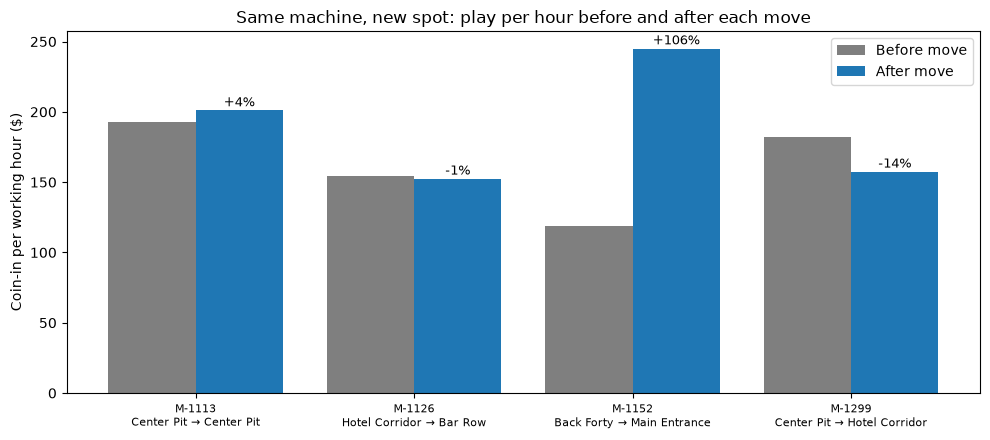

In [36]:
# Natural experiment: 4 machines moved to a new spot. Same machine, same game, different location.
placements = load("data/2_machine_decision/placements.parquet")
daily = load("data/1_prepared_views/prepared_daily_view.parquet")
d = daily[daily["active"]].copy()

counts = placements["machine_id"].value_counts()
movers = placements[placements["machine_id"].isin(counts[counts > 1].index)] \
            .sort_values(["machine_id", "effective_from_utc"])

def rates(x):
    return pd.Series({"coin_hr": x["coin_in_usd"].sum() / x["available_hours"].sum(),
                      "theo_hr": x["theo_usd"].sum() / x["available_hours"].sum(),
                      "occupancy": x["occupied_hours"].sum() / x["available_hours"].sum()})

rows = []
for mid, g in movers.groupby("machine_id"):
    move_day = d.loc[(d["machine_id"] == mid) & (d["location_id"] == g["location_id"].iloc[-1]), "gaming_date"].min()
    m = d[d["machine_id"] == mid]
    before, after = m[m["gaming_date"] < move_day], m[m["gaming_date"] > move_day]   # skip the move day itself
    old_bank, new_bank = before["bank_id"].iloc[0], after["bank_id"].iloc[0]

    # Neighbours: the other machines in the old and new bank, on the same days as each period
    nb_before = d[(d["bank_id"] == old_bank) & (d["machine_id"] != mid) & d["gaming_date"].isin(before["gaming_date"])]
    nb_after  = d[(d["bank_id"] == new_bank) & (d["machine_id"] != mid) & d["gaming_date"].isin(after["gaming_date"])]

    mb, ma, nbb, nba = rates(before), rates(after), rates(nb_before), rates(nb_after)
    rows.append({"machine": mid, "game": m["theme"].iloc[0],
                 "from": before["zone_name"].iloc[0], "to": after["zone_name"].iloc[0], "move_day": move_day,
                 "days_before": len(before), "days_after": len(after),
                 "coin_hr_before": mb["coin_hr"], "coin_hr_after": ma["coin_hr"],
                 "change": ma["coin_hr"] / mb["coin_hr"] - 1,
                 "occ_before": mb["occupancy"], "occ_after": ma["occupancy"],
                 "vs_neighbours_before": mb["coin_hr"] / nbb["coin_hr"],
                 "vs_neighbours_after": ma["coin_hr"] / nba["coin_hr"],
                 "theo_hr_change_usd": ma["theo_hr"] - mb["theo_hr"]})

moves = pd.DataFrame(rows).set_index("machine")
pd.set_option("display.width", 250)
print(moves.round(3).to_string())

print("\nHow to read it:")
print("  change               = the machine's own play per working hour, after vs before the move")
print("  vs_neighbours_before = machine ÷ the other machines in its OLD bank (same days); 1.0 = same as neighbours")
print("  vs_neighbours_after  = machine ÷ the other machines in its NEW bank (same days)")
print("  If location drives play, the machine jumps to its new neighbours' level, so both ratios stay near 1.0")

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(moves))
ax.bar(x - 0.2, moves["coin_hr_before"], 0.4, label="Before move", color="tab:gray")
ax.bar(x + 0.2, moves["coin_hr_after"], 0.4, label="After move", color="tab:blue")
for i, (mid, row) in enumerate(moves.iterrows()):
    ax.text(i + 0.2, row["coin_hr_after"] + 3, f"{row['change']:+.0%}", ha="center", fontsize=9)
ax.set_xticks(x, [f"{mid}\n{row['from']} → {row['to']}" for mid, row in moves.iterrows()], fontsize=8)
ax.set_ylabel("Coin-in per working hour ($)")
ax.set_title("Same machine, new spot: play per hour before and after each move")
ax.legend()
plt.tight_layout()
plt.show()

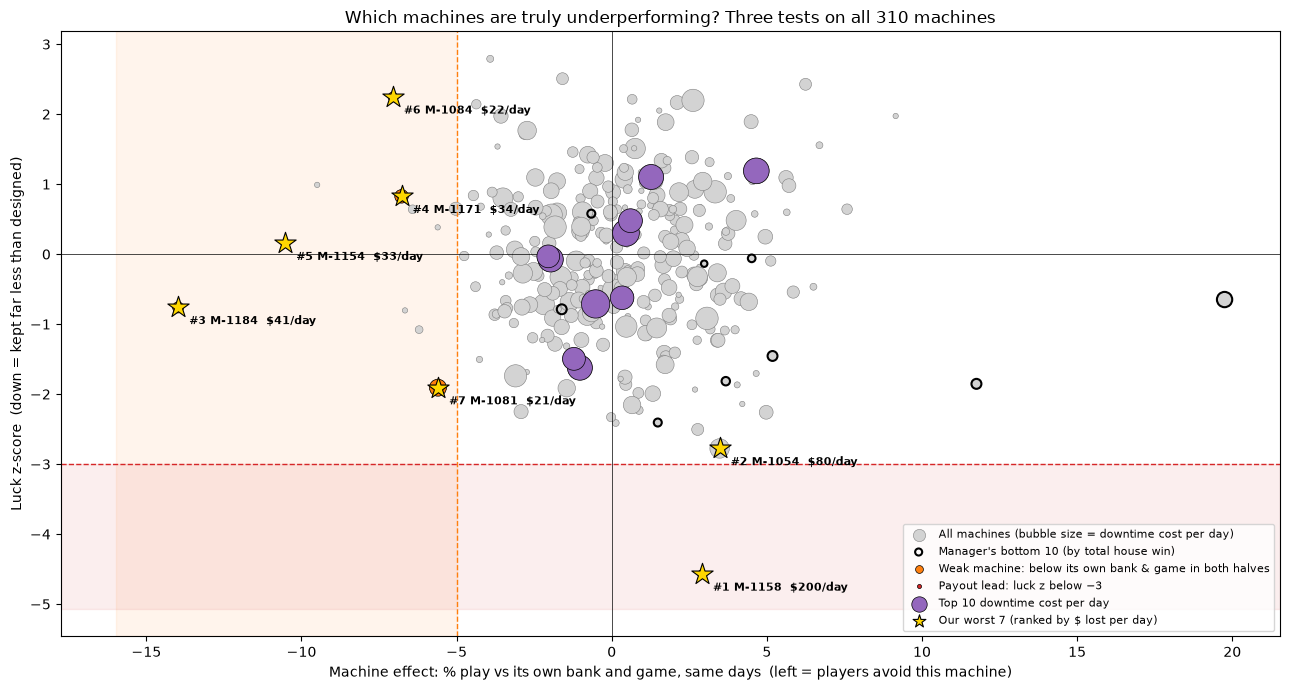

Our worst 7 machines:
        rank                     problem             zone            theme  machine_effect      z  lost_per_day  in manager's 10
M-1158     1                 Payout lead       Back Forty      Desert Gold           0.029 -4.570       199.805             True
M-1054     2  Payout (borderline, watch)  Garage Entrance  Prairie Thunder           0.035 -2.776        80.267            False
M-1184     3                Weak machine       Back Forty   Jackpot Summit          -0.140 -0.761        40.642            False
M-1171     4                Weak machine          Bar Row  Prairie Thunder          -0.068  0.826        33.815            False
M-1154     5                Weak machine       Back Forty   Jackpot Summit          -0.105  0.155        33.489            False
M-1084     6                Weak machine   Hotel Corridor   Lucky Lanterns          -0.071  2.247        22.023            False
M-1081     7                Weak machine    Main Entrance   Lucky Lanterns 

In [37]:
# All machines on the three tests: weak machine (x), payout lead (y), downtime cost (bubble size)
cal = load("data/2_machine_decision/calendar_day.parquet")
dt3 = daily[daily["active"]].merge(cal[["gaming_date", "scheduled_seconds"]], on="gaming_date")
dt3["down_hrs"] = dt3["scheduled_seconds"] / 3600 - dt3["available_hours"]
per_m = dt3.groupby("machine_id").agg(theo=("theo_usd", "sum"), avail=("available_hours", "sum"),
                                      down=("down_hrs", "sum"), days=("gaming_date", "count"),
                                      zone=("zone_name", "last"), theme=("theme", "first"),
                                      house_win=("house_win_usd", "sum"))
per_m["lost_theo_per_day"] = per_m["down"] * per_m["theo"] / per_m["avail"] / per_m["days"]

three = per_m.join(me[["machine_effect"]]).join(lk[["z"]])     # me: machine effects (Model 2), lk: luck test
manager_10 = three.nsmallest(10, "house_win").index

weak_ids = three.index[(three["machine_effect"] < -0.05) & three.index.isin(weak.index)]   # weak in both halves
payout  = three.index[three["z"] < -3]
downtime = three.nlargest(10, "lost_theo_per_day").index

size = 15 + 400 * three["lost_theo_per_day"] / three["lost_theo_per_day"].max()
fig, ax = plt.subplots(figsize=(13, 7))
ax.axvspan(three["machine_effect"].min() * 100 - 2, -5, color="tab:orange", alpha=0.08)
ax.axhspan(three["z"].min() - 0.5, -3, color="tab:red", alpha=0.08)
ax.scatter(three["machine_effect"] * 100, three["z"], s=size, color="lightgray", edgecolor="gray",
           linewidth=0.4, label="All machines (bubble size = downtime cost per day)")
ax.scatter(three.loc[manager_10, "machine_effect"] * 100, three.loc[manager_10, "z"], s=size[manager_10],
           facecolor="none", edgecolor="black", linewidth=1.5, label="Manager's bottom 10 (by total house win)")
for ids, col, lab in [(weak_ids, "tab:orange", "Weak machine: below its own bank & game in both halves"),
                      (payout, "tab:red", "Payout lead: luck z below −3"),
                      (downtime, "tab:purple", "Top 10 downtime cost per day")]:
    ax.scatter(three.loc[ids, "machine_effect"] * 100, three.loc[ids, "z"], s=size[ids], color=col,
               edgecolor="black", linewidth=0.5, label=lab, zorder=3)
# ---- Our worst 7: only problems that passed a test, ranked by expected win lost per day ----
per_day = daily[daily["active"]].groupby("machine_id").agg(hw=("house_win_usd", "sum"), th=("theo_usd", "sum"),
                                                          n=("gaming_date", "count"))
borderline = three.drop(payout).nsmallest(1, "z").index            # next-most-extreme payout result: watch
ours = pd.DataFrame(index=list(payout) + list(borderline) + list(weak_ids))
ours["problem"] = ["Payout lead" if m in payout else "Payout (borderline, watch)" if m in borderline
                   else "Weak machine" for m in ours.index]
ours["lost_per_day"] = [(per_day.loc[m, "th"] - per_day.loc[m, "hw"]) / per_day.loc[m, "n"] if "Payout" in p
                        else -three.loc[m, "machine_effect"] * per_day.loc[m, "th"] / per_day.loc[m, "n"]
                        for m, p in zip(ours.index, ours["problem"])]
ours = ours.join(three[["zone", "theme", "machine_effect", "z"]]).sort_values("lost_per_day", ascending=False)
ours["rank"] = range(1, len(ours) + 1)
ours["in manager's 10"] = ours.index.isin(manager_10)

ax.scatter(three.loc[ours.index, "machine_effect"] * 100, three.loc[ours.index, "z"], s=260, marker="*",
           color="gold", edgecolor="black", linewidth=0.8, zorder=4, label=f"Our worst {len(ours)} (ranked by $ lost per day)")
for mid, row in ours.iterrows():
    ax.annotate(f"#{row['rank']} {mid}  ${row['lost_per_day']:,.0f}/day",
                (three.loc[mid, "machine_effect"] * 100, three.loc[mid, "z"]),
                xytext=(8, -12), textcoords="offset points", fontsize=8, fontweight="bold")

ax.axvline(-5, color="tab:orange", linestyle="--", linewidth=1)
ax.axhline(-3, color="tab:red", linestyle="--", linewidth=1)
ax.axhline(0, color="black", linewidth=0.5); ax.axvline(0, color="black", linewidth=0.5)
ax.set_xlabel("Machine effect: % play vs its own bank and game, same days  (left = players avoid this machine)")
ax.set_ylabel("Luck z-score  (down = kept far less than designed)")
ax.set_title("Which machines are truly underperforming? Three tests on all 310 machines")
ax.legend(loc="lower right", fontsize=8, markerscale=0.6)
plt.tight_layout()
plt.show()

print(f"Our worst {len(ours)} machines:")
print(ours[["rank", "problem", "zone", "theme", "machine_effect", "z", "lost_per_day", "in manager's 10"]].round(3).to_string())
overlap = int(ours["in manager's 10"].sum())
print(f"\nOverlap with the manager's bottom 10: {overlap} machine(s)\n")

flagged = sorted(set(weak_ids) | set(payout) | set(downtime))
tbl = three.loc[flagged, ["zone", "theme", "machine_effect", "z", "lost_theo_per_day"]].copy()
tbl["weak"] = tbl.index.isin(weak_ids); tbl["payout lead"] = tbl.index.isin(payout); tbl["top downtime"] = tbl.index.isin(downtime)
tbl["in manager's 10"] = tbl.index.isin(manager_10)
print(tbl.round(3).sort_values("machine_effect").to_string())

**M-1152 moved from Back Forty to Main Entrance and doubled its play** (+106%, occupancy 17% → 34%, about +$15 theo per working hour). The regression's zone effects predicted all four moves closely (+93% predicted vs +106% actual for M-1152, −12% vs −14% for M-1299).
Constraint: there are **no empty slots** left in Main Entrance or Center Pit, so further moves would be swaps that mostly reshuffle play.

### Q1 answer
- **None of the manager's bottom 10 is a weak machine.** All 10 are normal for their bank and game: 7 are low because they sit in **Back Forty**, 3 because they were on the floor for **only part of the period**.
- **Location and game explain about 96%** of the differences between machines; the machine itself about 1%.
- **Back Forty is 36% below the floor average**, almost entirely from empty seats. The move of M-1152 confirms that the same machine doubles its play elsewhere.
- **Only 5 machines are truly weaker than their neighbours** in both halves (by 6–14%), led by M-1184 and M-1154.
- **One payout lead: M-1158**, to inspect rather than replace.
- **Replacing machines barely helped** in the two real swaps.

---
## 3. Q2: What changed in demand, and why?
Event lift = coin-in on event days vs a normal day with the same weekday; extra theo = the additional *expected* win (luck removed).

In [38]:
import decimal
import pandas as pd

def load(path):
    """Read a parquet file and turn exact-decimal money columns into normal numbers."""
    df = pd.read_parquet(path)
    for c in df.columns:
        if df[c].dtype == object and df[c].dropna().map(type).eq(decimal.Decimal).any():
            df[c] = df[c].astype(float)
    return df

prop   = load("data/1_prepared_views/property_day.parquet")
events = load("data/4_context/events.parquet")
print(events[["name", "event_type", "start_date", "end_date", "announced_date"]])
print()

# Normal level = average for each weekday on days with no event
no_event = prop["events_active"].isna() | (prop["events_active"].astype(str).str.strip().isin(["", "0", "None", "[]"]))
normal = prop[no_event].groupby("local_weekday")[["coin_in_usd", "theo_usd"]].mean()

# Lift for each event vs a normal day with the same weekday
for _, e in events.iterrows():
    days = prop[(prop["gaming_date"] >= e["start_date"]) & (prop["gaming_date"] <= e["end_date"])]
    if days.empty:
        print(f"{e['name'][:40]:40} no matching days")
        continue
    base = normal.loc[days["local_weekday"]].sum()
    extra_theo = days["theo_usd"].sum() - base["theo_usd"]
    lift = days["coin_in_usd"].sum() / base["coin_in_usd"] - 1
    print(f"{e['name'][:40]:40} {len(days)} days  {lift:+.0%} coin-in   extra theo ≈ ${extra_theo:,.0f}")

                                           name          event_type  start_date    end_date announced_date
0                                           CES          convention  2025-01-07  2025-01-10     2024-01-12
1                        Super Bowl LIX weekend      sports_viewing  2025-02-07  2025-02-09     2024-01-01
2  College basketball tournament opening rounds      sports_viewing  2025-03-20  2025-03-23     2024-12-01
3                                     CinemaCon          convention  2025-03-31  2025-04-03     2024-04-15
4                                      NAB Show          convention  2025-04-05  2025-04-09     2024-04-20
5                EDC Las Vegas festival weekend            festival  2025-05-16  2025-05-18     2024-05-20
6             Gilded Ace Winter Slot Tournament  property_promotion  2025-02-21  2025-02-23     2025-01-20
7           Gilded Ace Locals Appreciation Week  property_promotion  2025-06-09  2025-06-15     2025-05-26

CES                                 

### Q2 answer
- **Demand was stable:** strong weekly rhythm, no long-term decline (June ran about 3% soft, see `model.ipynb`).
- **Sports weekends drove the biggest spikes:** Super Bowl +23%, college basketball +19%. EDC added +16%.
- **The casino's own Winter Tournament (+18%, about $83K extra theo) worked as well as a major outside event.** The week-long Locals Appreciation Week added only +4%.
- **Conventions barely moved play** (CES +1%, CinemaCon +3%, NAB +6%).
- Every event was announced well in advance, so events are a valid forecast input.

---
## 4. Q3: How much play was lost to downtime, and when?
Lost expected win = downtime hours × the machine's normal theo per working hour. Theo is used instead of actual win so luck doesn't distort it.

Total downtime: 5,021 machine-hours
Lost expected win: $90,313  (0.38% of all expected win)



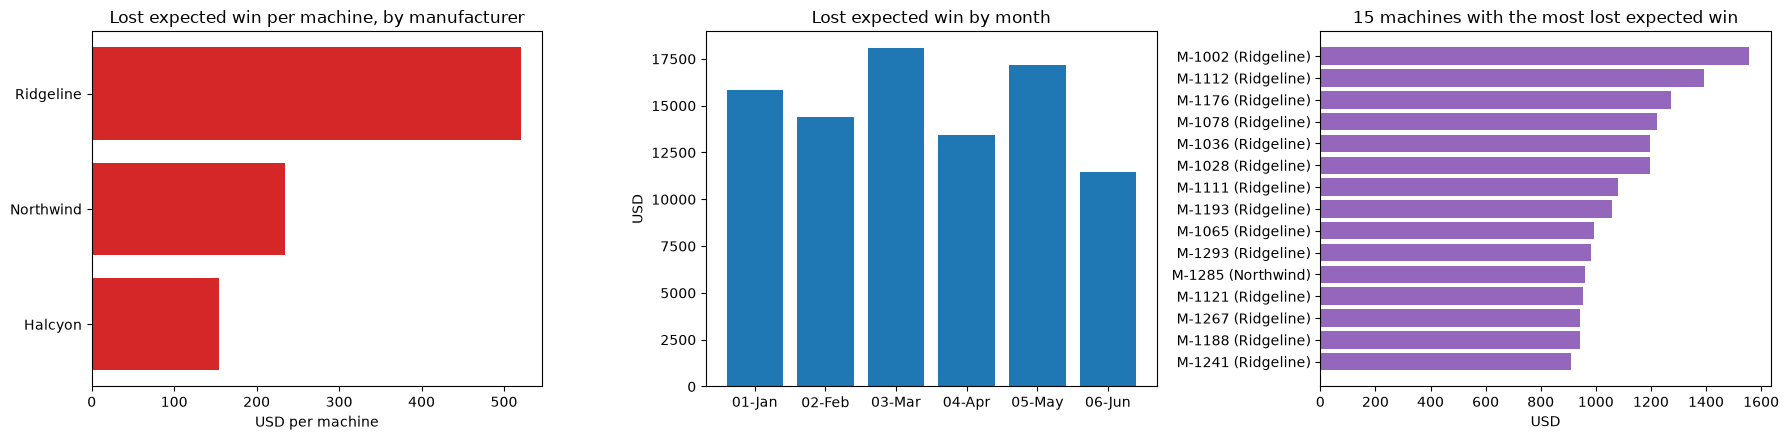

                       tickets  median_hrs_down  total_hrs_down
event_type                                                     
fault_repair              1207              3.2          4934.1
install                     10              6.0            60.0
move                         4              3.0            12.0
retire                       2              0.0             0.0
scheduled_maintenance        3              5.0            15.0


In [39]:
import matplotlib.pyplot as plt

daily = load("data/1_prepared_views/prepared_daily_view.parquet")
d = daily[daily["active"]]
cal = load("data/2_machine_decision/calendar_day.parquet")
ops = load("data/2_machine_decision/operations.parquet")

dt = d.merge(cal[["gaming_date", "scheduled_seconds"]], on="gaming_date").copy()
dt["down_hrs"] = dt["scheduled_seconds"] / 3600 - dt["available_hours"]

# Each machine's normal expected win per working hour
rate = dt.groupby("machine_id").apply(lambda g: g["theo_usd"].sum() / g["available_hours"].sum()).rename("theo_per_hr")
dt = dt.join(rate, on="machine_id")
dt["lost_theo"] = dt["down_hrs"] * dt["theo_per_hr"]

print(f"Total downtime: {dt['down_hrs'].sum():,.0f} machine-hours")
print(f"Lost expected win: ${dt['lost_theo'].sum():,.0f}  "
      f"({dt['lost_theo'].sum() / dt['theo_usd'].sum():.2%} of all expected win)\n")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1) By manufacturer (preventive maintenance is bought per manufacturer)
by_mfr = dt.groupby("manufacturer").agg(lost=("lost_theo", "sum"), machines=("machine_id", "nunique"))
by_mfr["lost_per_machine"] = by_mfr["lost"] / by_mfr["machines"]
by_mfr = by_mfr.sort_values("lost_per_machine")
axes[0].barh(by_mfr.index, by_mfr["lost_per_machine"], color="tab:red")
axes[0].set_title("Lost expected win per machine, by manufacturer")
axes[0].set_xlabel("USD per machine")

# 2) By month
dt["month_name"] = pd.to_datetime(dt["gaming_date"]).dt.strftime("%m-%b")
by_month = dt.groupby("month_name")["lost_theo"].sum()
axes[1].bar(by_month.index, by_month.values, color="tab:blue")
axes[1].set_title("Lost expected win by month")
axes[1].set_ylabel("USD")

# 3) Top 15 machines
top = dt.groupby("machine_id").agg(lost=("lost_theo", "sum"), zone=("zone_name", "last"),
                                   mfr=("manufacturer", "first")).nlargest(15, "lost")
axes[2].barh([f"{i} ({row.mfr})" for i, row in top.iterrows()][::-1], top["lost"][::-1], color="tab:purple")
axes[2].set_title("15 machines with the most lost expected win")
axes[2].set_xlabel("USD")

plt.tight_layout()
plt.show()

# What kinds of tickets, and how long machines were down for each
ops["hours_down"] = (pd.to_datetime(ops["available_at_utc"]) - pd.to_datetime(ops["opened_at_utc"])).dt.total_seconds() / 3600
print(ops.groupby("event_type").agg(tickets=("operation_id", "count"),
                                    median_hrs_down=("hours_down", "median"),
                                    total_hrs_down=("hours_down", "sum")).round(1))

### Q3 answer
- **$90,313 of expected win was lost**, only **0.38%** of the total. Machines were available about 99.5% of the time.
- **Ridgeline machines lose about 2–3× more per machine** than Northwind or Halcyon; 14 of the 15 worst machines are Ridgeline (the two retired machines were Ridgelines from 2018–2019).
- **No trend over time:** monthly losses ranged from about $11K to $18K.
- Assumption: a broken machine would have been played at its average rate. Breakdowns at quiet hours would mean a smaller real loss.

---
## 5. Q4: What did tracked players wager, get back and net?
Loyalty-card players only, so totals don't match machine meters (expected).

Players: 113,890
Total wagered: $163,804,870   Paid back: $148,219,409   Net player loss: $15,585,461
Players who came out ahead: 13.6%
Median player result: lost $72

Top 1% of losing players account for 15.7% of all losses
Top 5% of losing players account for 40.7% of all losses
Top 10% of losing players account for 52.8% of all losses
Top 20% of losing players account for 66.5% of all losses


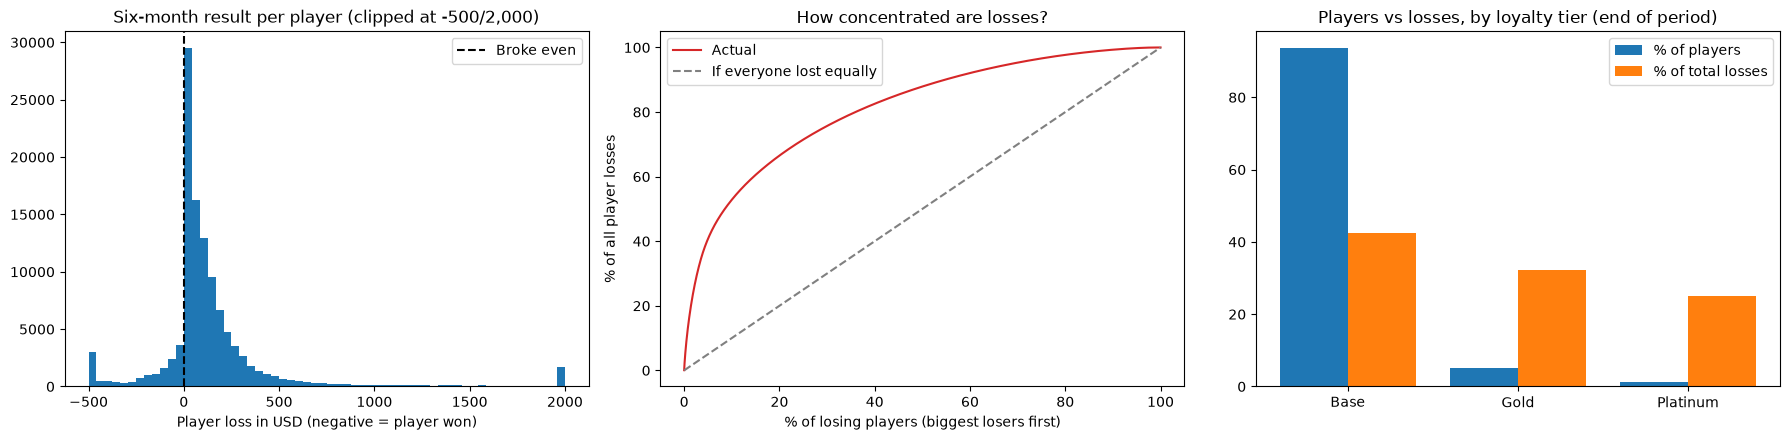

In [40]:
import matplotlib.pyplot as plt
import numpy as np

pp = load("data/1_prepared_views/player_period.parquet")

# One row per player for the full six months
pl = pp.groupby("player_id").agg(
    coin_in=("tracked_coin_in_usd", "sum"),
    payout=("tracked_payout_usd", "sum"),
    theo=("theo_usd", "sum"),
    visits=("observed_visits", "sum"),
    tier=("tier_end", "last"),
    age_band=("age_band", "first"),
    region=("home_region", "first"),
)
pl["player_loss"] = pl["coin_in"] - pl["payout"]      # positive = player lost money

n = len(pl)
print(f"Players: {n:,}")
print(f"Total wagered: ${pl['coin_in'].sum():,.0f}   Paid back: ${pl['payout'].sum():,.0f}   "
      f"Net player loss: ${pl['player_loss'].sum():,.0f}")
print(f"Players who came out ahead: {(pl['player_loss'] < 0).mean():.1%}")
print(f"Median player result: lost ${pl['player_loss'].median():,.0f}\n")

# Concentration: what share of all losses comes from the biggest losers?
losers = pl.loc[pl["player_loss"] > 0, "player_loss"].sort_values(ascending=False)
for pct in [0.01, 0.05, 0.10, 0.20]:
    k = max(1, int(len(losers) * pct))
    print(f"Top {pct:.0%} of losing players account for {losers.iloc[:k].sum() / losers.sum():.1%} of all losses")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1) Distribution of results (clipped so the middle is visible)
axes[0].hist(pl["player_loss"].clip(-500, 2000), bins=60, color="tab:blue")
axes[0].axvline(0, color="black", linestyle="--", label="Broke even")
axes[0].set_title("Six-month result per player (clipped at -$500 / $2,000)")
axes[0].set_xlabel("Player loss in USD (negative = player won)")
axes[0].legend()

# 2) Concentration curve
cum = losers.cumsum() / losers.sum()
share_players = np.arange(1, len(losers) + 1) / len(losers)
axes[1].plot(share_players * 100, cum * 100, color="tab:red", label="Actual")
axes[1].plot([0, 100], [0, 100], color="gray", linestyle="--", label="If everyone lost equally")
axes[1].set_title("How concentrated are losses?")
axes[1].set_xlabel("% of losing players (biggest losers first)")
axes[1].set_ylabel("% of all player losses")
axes[1].legend()

# 3) By loyalty tier
by_tier = pl.groupby("tier").agg(players=("player_loss", "size"), total_loss=("player_loss", "sum"))
by_tier["share_players"] = by_tier["players"] / by_tier["players"].sum() * 100
by_tier["share_loss"] = by_tier["total_loss"] / by_tier["total_loss"].sum() * 100
x = np.arange(len(by_tier))
axes[2].bar(x - 0.2, by_tier["share_players"], 0.4, label="% of players")
axes[2].bar(x + 0.2, by_tier["share_loss"], 0.4, label="% of total losses")
axes[2].set_xticks(x, by_tier.index)
axes[2].set_title("Players vs losses, by loyalty tier (end of period)")
axes[2].legend()

plt.tight_layout()
plt.show()

### Q4 answer
- Card players wagered **$163.8M**, got back **$148.2M**, and lost **$15.6M** (about 9.5%).
- The **median player lost $72** over six months; **13.6% came out ahead**.
- **Losses are concentrated:** the top 10% of losing players account for **53%** of losses; Gold and Platinum are about 6% of players but about 57% of losses (tiers are earned by playing, so this is association, not cause).
- In line with the rules, we suggest only **protective** ideas for heavy losers, never ideas that push them to gamble more.

---
## 6. Q5: What did the comp program cost, and did anything change?

Comp cost from property_day:   $190,669
Comp cost from loyalty_ledger: $190,669

Share of comp cost by tier:
tier
Base        38.6%
Gold        49.7%
Platinum    11.7%
dtype: str


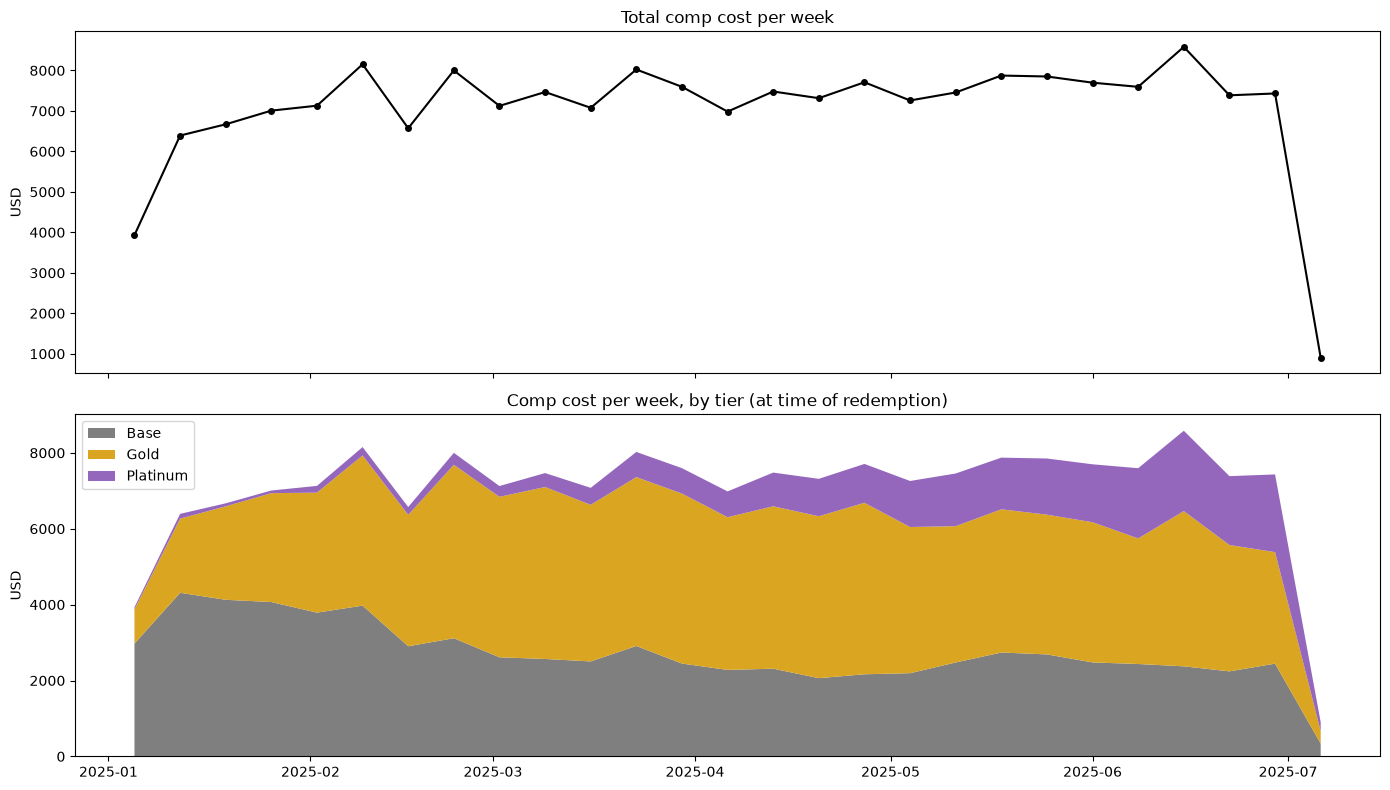

In [41]:
import matplotlib.pyplot as plt

prop = load("data/1_prepared_views/property_day.parquet")
led  = load("data/3_guests/loyalty_ledger.parquet")

# Keep only rows that cost the casino something (redeemed comps)
c = led[led["economic_cost_cents"].fillna(0) > 0].copy()
c["cost_usd"] = c["economic_cost_cents"] / 100

# UTC -> Las Vegas local time -> gaming day (6 a.m. to 6 a.m.)
local = pd.to_datetime(c["event_at_utc"], utc=True).dt.tz_convert("America/Los_Angeles")
c["gaming_date"] = (local - pd.Timedelta(hours=6)).dt.date
c["tier"] = c["tier_before"]

# Check: ledger total should be close to the property total
print(f"Comp cost from property_day:   ${prop['comp_cost_usd'].sum():,.0f}")
print(f"Comp cost from loyalty_ledger: ${c['cost_usd'].sum():,.0f}\n")

# Weekly total (property_day)
p = prop.set_index(pd.to_datetime(prop["gaming_date"]))
weekly_total = p["comp_cost_usd"].resample("W").sum()

# Weekly by tier (loyalty_ledger)
by_tier = c.pivot_table(index="gaming_date", columns="tier", values="cost_usd", aggfunc="sum").fillna(0)
by_tier.index = pd.to_datetime(by_tier.index)
tier_order = [t for t in ["Base", "Gold", "Platinum"] if t in by_tier.columns] + \
             [t for t in by_tier.columns if t not in ["Base", "Gold", "Platinum"]]
weekly_tier = by_tier[tier_order].resample("W").sum()

print("Share of comp cost by tier:")
print((weekly_tier.sum() / weekly_tier.sum().sum() * 100).round(1).astype(str) + "%")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# 1) Total comp cost per week
axes[0].plot(weekly_total.index, weekly_total.values, color="black", marker="o", markersize=4)
axes[0].set_title("Total comp cost per week")
axes[0].set_ylabel("USD")

# 2) Comp cost per week, stacked by tier
axes[1].stackplot(weekly_tier.index, weekly_tier.T.values, labels=weekly_tier.columns,
                  colors=["tab:gray", "goldenrod", "tab:purple"][:len(weekly_tier.columns)])
axes[1].set_title("Comp cost per week, by tier (at time of redemption)")
axes[1].set_ylabel("USD")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

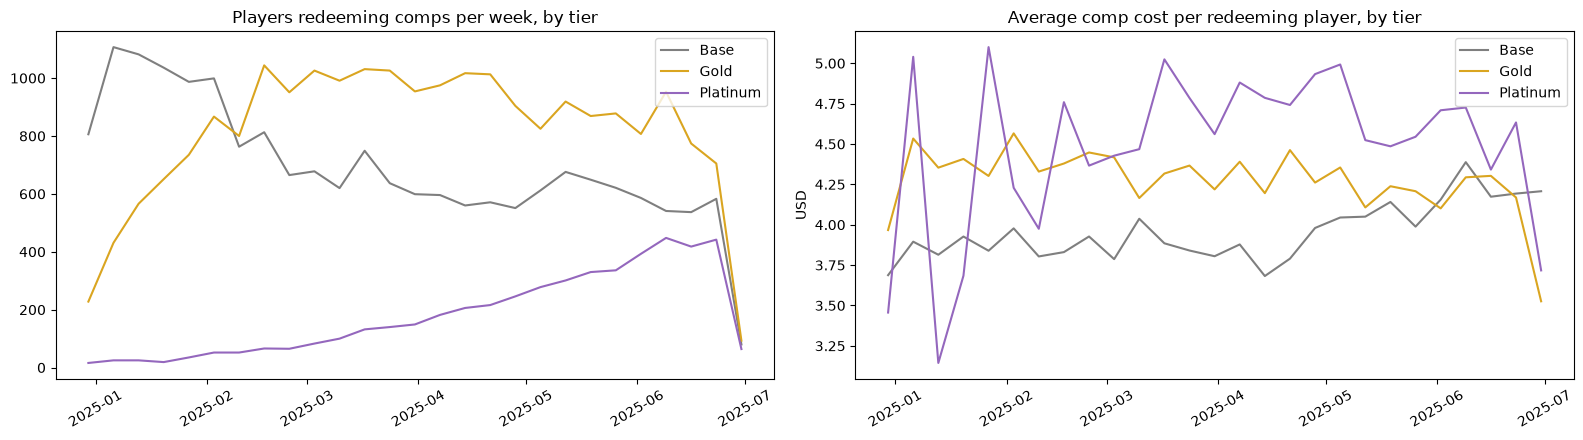

In [42]:
# Weekly: how many players redeemed in each tier, and how much each got on average
c["week"] = pd.to_datetime(c["gaming_date"]).dt.to_period("W").dt.start_time
w = c.groupby(["week", "tier"]).agg(players=("player_id", "nunique"), cost=("cost_usd", "sum")).reset_index()
w["cost_per_player"] = w["cost"] / w["players"]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
colors = {"Base": "tab:gray", "Gold": "goldenrod", "Platinum": "tab:purple"}
for t, g in w.groupby("tier"):
    axes[0].plot(g["week"], g["players"], label=t, color=colors.get(t))
    axes[1].plot(g["week"], g["cost_per_player"], label=t, color=colors.get(t))
axes[0].set_title("Players redeeming comps per week, by tier")
axes[1].set_title("Average comp cost per redeeming player, by tier")
axes[1].set_ylabel("USD")
for ax in axes:
    ax.legend()
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

In [43]:
pp = load("data/1_prepared_views/player_period.parquet")
mo = pp.groupby("period_month").agg(points=("points_earned", "sum"),
                                    coin_in=("tracked_coin_in_usd", "sum"),
                                    comp_cost=("comp_cost_usd", "sum"),
                                    theo=("theo_usd", "sum"))
mo["points_per_100_bet"] = mo["points"] / mo["coin_in"] * 100
mo["comp_cost_pct_of_theo"] = mo["comp_cost"] / mo["theo"] * 100
print(mo[["points_per_100_bet", "comp_cost_pct_of_theo"]].round(3))
#hellooo

              points_per_100_bet  comp_cost_pct_of_theo
period_month                                           
2025-01                   99.880                  1.114
2025-02                   99.886                  1.204
2025-03                   99.889                  1.217
2025-04                   99.887                  1.242
2025-05                   99.885                  1.296
2025-06                   99.886                  1.317


              points_per_comp_dollar  redemptions_per_day  comp_cost_per_day  avg_comp_face_usd
period                                                                                         
Before May 1                   13.09               321.62            1027.09              11.45
May 1 onward                    5.78               340.43            1105.23              11.61

Points per $1 of comp, by loyalty tier:
period       Before May 1  May 1 onward
tier_before                            
Base                 15.0          7.00
Gold                 12.0          5.66
Platinum              9.0          4.22


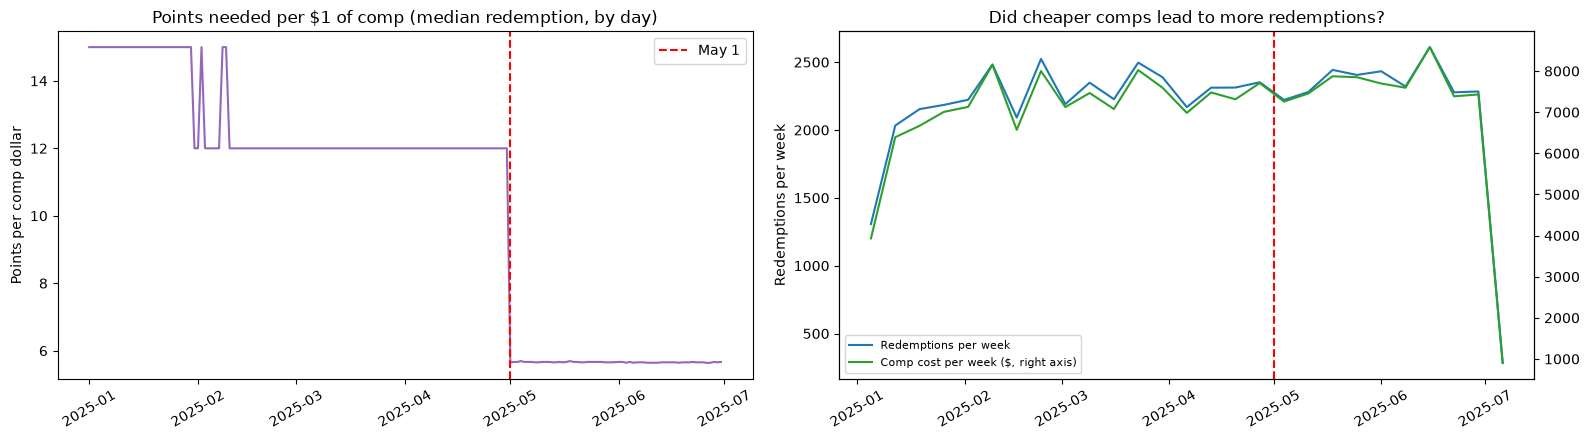

In [45]:
# Did the PRICE of comps in points change? Points redeemed per $1 of comp value, by gaming day
led = load("data/3_guests/loyalty_ledger.parquet")
red = led[led["event_type"] == "redeem"].copy()
local = pd.to_datetime(red["event_at_utc"], utc=True).dt.tz_convert("America/Los_Angeles")
red["gaming_date"] = pd.to_datetime((local - pd.Timedelta(hours=6)).dt.date)
red = red[red["gaming_date"] <= "2025-06-30"]
red["points_per_comp_dollar"] = -red["points_delta"] / (red["face_value_cents"] / 100)

by_day = red.groupby("gaming_date").agg(points_per_dollar=("points_per_comp_dollar", "median"),
                                        redemptions=("points_delta", "size"),
                                        face_usd=("face_value_cents", lambda s: s.sum() / 100),
                                        cost_usd=("economic_cost_cents", lambda s: s.sum() / 100))
red["period"] = np.where(red["gaming_date"] >= "2025-05-01", "May 1 onward", "Before May 1")
summary = red.groupby("period").agg(days=("gaming_date", "nunique"), redemptions=("points_delta", "size"),
                                    points=("points_delta", lambda s: -s.sum()),
                                    face_usd=("face_value_cents", lambda s: s.sum() / 100),
                                    cost_usd=("economic_cost_cents", lambda s: s.sum() / 100))
summary["points_per_comp_dollar"] = summary["points"] / summary["face_usd"]
summary["redemptions_per_day"] = summary["redemptions"] / summary["days"]
summary["comp_cost_per_day"] = summary["cost_usd"] / summary["days"]
summary["avg_comp_face_usd"] = summary["face_usd"] / summary["redemptions"]
print(summary[["points_per_comp_dollar", "redemptions_per_day", "comp_cost_per_day", "avg_comp_face_usd"]].round(2).to_string())

print("\nPoints per $1 of comp, by loyalty tier:")
print(red.pivot_table(index="tier_before", columns="period", values="points_per_comp_dollar", aggfunc="median").round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(by_day.index, by_day["points_per_dollar"], color="tab:purple")
axes[0].axvline(pd.Timestamp("2025-05-01"), color="red", linestyle="--", label="May 1")
axes[0].set_title("Points needed per $1 of comp (median redemption, by day)")
axes[0].set_ylabel("Points per comp dollar")
axes[0].legend()
weekly = by_day.resample("W")[["redemptions", "cost_usd"]].sum()
axes[1].plot(weekly.index, weekly["redemptions"], color="tab:blue", label="Redemptions per week")
axes[1].axvline(pd.Timestamp("2025-05-01"), color="red", linestyle="--")
axes[1].set_title("Did cheaper comps lead to more redemptions?")
axes[1].set_ylabel("Redemptions per week")
ax_r = axes[1].twinx()
ax_r.plot(weekly.index, weekly["cost_usd"], color="tab:green", label="Comp cost per week ($, right axis)")
h1, l1 = axes[1].get_legend_handles_labels(); h2, l2 = ax_r.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, loc="lower left", fontsize=8)
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### Q5 answer
- The comp program cost **$190,669** over six months, about **1.1–1.3% of expected win**.
- **The earn rate never changed** (about 1 point per $1 wagered every month).
- **The redemption price changed on May 1.** The points needed per $1 of comp were cut by about 53% in every tier (Base 15 → 7, Gold 12 → 5.66, Platinum 9 → 4.22). This was a deliberate policy change: earn rates, comp values and the casino's cost per comp didn't move.
- **Effect of the change:** slightly more players redeemed (23% → 25%) and comp cost rose about 8%, but visits per player, coin-in per player, carded share and floor play showed **no measurable lift**. With two months of data and no control group, the effect on play is unproven.
- **Before May, the cost share rose gradually** (1.11% → 1.24% of theo) because players **moved up tiers**: Platinum redeemers grew from about 20 to 450 per week while cost per redeeming player stayed roughly flat within each tier.
- **Risk to flag:** each unredeemed point is now worth about twice as much in comps, so the potential future cost of saved points has roughly doubled.

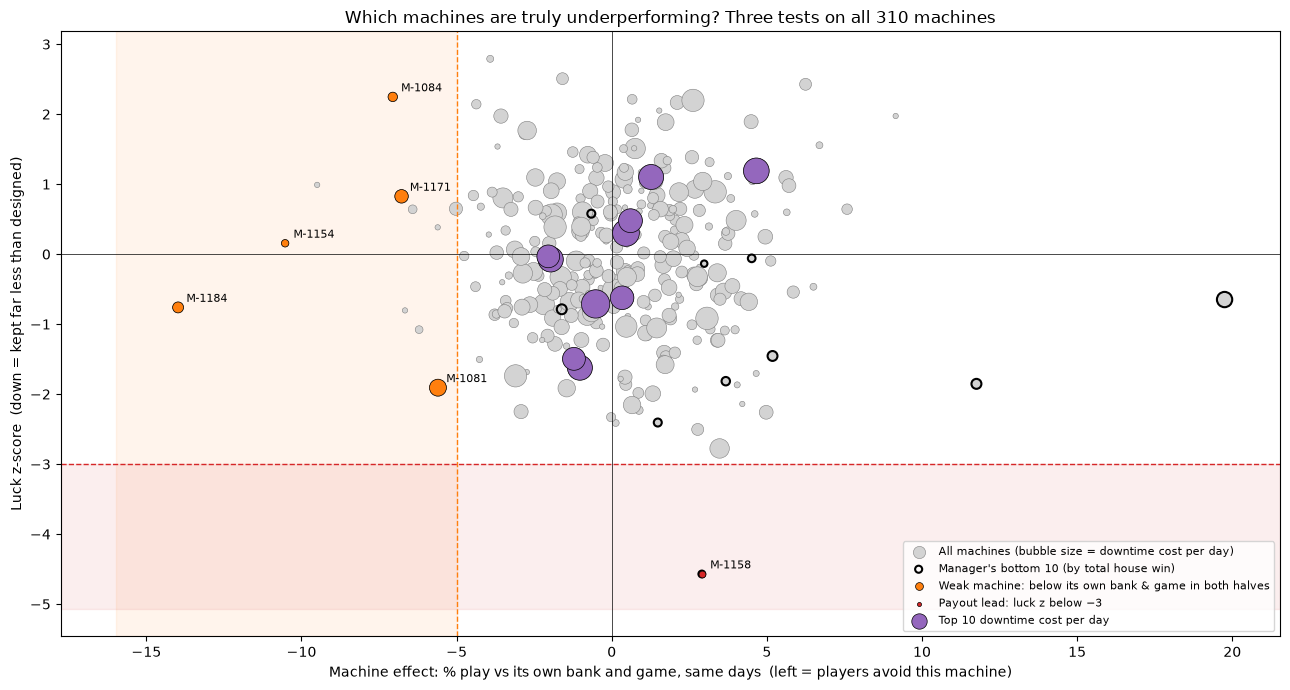

                       zone            theme  machine_effect      z  lost_theo_per_day   weak  payout lead  top downtime  in manager's 10
machine_id                                                                                                                               
M-1184           Back Forty   Jackpot Summit          -0.140 -0.761              1.006   True        False         False            False
M-1154           Back Forty   Jackpot Summit          -0.105  0.155              0.293   True        False         False            False
M-1084       Hotel Corridor   Lucky Lanterns          -0.071  2.247              0.662   True        False         False            False
M-1171              Bar Row  Prairie Thunder          -0.068  0.826              1.696   True        False         False            False
M-1081        Main Entrance   Lucky Lanterns          -0.056 -1.908              2.862   True        False         False            False
M-1293      Garage Entrance      N

In [44]:
# All machines on the three tests: weak machine (x), payout lead (y), downtime cost (bubble size)
cal = load("data/2_machine_decision/calendar_day.parquet")
dt3 = daily[daily["active"]].merge(cal[["gaming_date", "scheduled_seconds"]], on="gaming_date")
dt3["down_hrs"] = dt3["scheduled_seconds"] / 3600 - dt3["available_hours"]
per_m = dt3.groupby("machine_id").agg(theo=("theo_usd", "sum"), avail=("available_hours", "sum"),
                                      down=("down_hrs", "sum"), days=("gaming_date", "count"),
                                      zone=("zone_name", "last"), theme=("theme", "first"),
                                      house_win=("house_win_usd", "sum"))
per_m["lost_theo_per_day"] = per_m["down"] * per_m["theo"] / per_m["avail"] / per_m["days"]

three = per_m.join(me[["machine_effect"]]).join(lk[["z"]])     # me: machine effects (Model 2), lk: luck test
manager_10 = three.nsmallest(10, "house_win").index

weak_ids = three.index[(three["machine_effect"] < -0.05) & three.index.isin(weak.index)]   # weak in both halves
payout  = three.index[three["z"] < -3]
downtime = three.nlargest(10, "lost_theo_per_day").index

size = 15 + 400 * three["lost_theo_per_day"] / three["lost_theo_per_day"].max()
fig, ax = plt.subplots(figsize=(13, 7))
ax.axvspan(three["machine_effect"].min() * 100 - 2, -5, color="tab:orange", alpha=0.08)
ax.axhspan(three["z"].min() - 0.5, -3, color="tab:red", alpha=0.08)
ax.scatter(three["machine_effect"] * 100, three["z"], s=size, color="lightgray", edgecolor="gray",
           linewidth=0.4, label="All machines (bubble size = downtime cost per day)")
ax.scatter(three.loc[manager_10, "machine_effect"] * 100, three.loc[manager_10, "z"], s=size[manager_10],
           facecolor="none", edgecolor="black", linewidth=1.5, label="Manager's bottom 10 (by total house win)")
for ids, col, lab in [(weak_ids, "tab:orange", "Weak machine: below its own bank & game in both halves"),
                      (payout, "tab:red", "Payout lead: luck z below −3"),
                      (downtime, "tab:purple", "Top 10 downtime cost per day")]:
    ax.scatter(three.loc[ids, "machine_effect"] * 100, three.loc[ids, "z"], s=size[ids], color=col,
               edgecolor="black", linewidth=0.5, label=lab, zorder=3)
for mid in set(weak_ids) | set(payout):
    ax.annotate(mid, (three.loc[mid, "machine_effect"] * 100, three.loc[mid, "z"]),
                xytext=(6, 4), textcoords="offset points", fontsize=8)
ax.axvline(-5, color="tab:orange", linestyle="--", linewidth=1)
ax.axhline(-3, color="tab:red", linestyle="--", linewidth=1)
ax.axhline(0, color="black", linewidth=0.5); ax.axvline(0, color="black", linewidth=0.5)
ax.set_xlabel("Machine effect: % play vs its own bank and game, same days  (left = players avoid this machine)")
ax.set_ylabel("Luck z-score  (down = kept far less than designed)")
ax.set_title("Which machines are truly underperforming? Three tests on all 310 machines")
ax.legend(loc="lower right", fontsize=8, markerscale=0.6)
plt.tight_layout()
plt.show()

flagged = sorted(set(weak_ids) | set(payout) | set(downtime))
tbl = three.loc[flagged, ["zone", "theme", "machine_effect", "z", "lost_theo_per_day"]].copy()
tbl["weak"] = tbl.index.isin(weak_ids); tbl["payout lead"] = tbl.index.isin(payout); tbl["top downtime"] = tbl.index.isin(downtime)
tbl["in manager's 10"] = tbl.index.isin(manager_10)
print(tbl.round(3).sort_values("machine_effect").to_string())

---
## 7. Q6: Which actions would we fund with $100,000, and how would we know they worked?

Rules: July 1–30, 2025; up to 3 action types from `action_catalog`; keeping money is valid. Budget = qty × (unit cost + daily cost × max(0, 30 − lead days)). Benefits count only for the days left after each action's lead time and are stated as **low / central / high** scenarios. Benefit = expected win (theo, so luck is excluded) + food-and-drink margin − extra comp cost.

machine  game             zone            designed  actual      z  machines this low by chance (of 310)  actually this low
M-1158   Desert Gold      Back Forty         10.0%    3.0%  -4.57                                  0.00                  1
M-1054   Prairie Thunder  Garage Entrance    11.0%    9.0%  -2.78                                  0.85                  2
M-1210   Royal Draw       Main Entrance       5.0%    3.6%  -2.50                                  1.90                  3


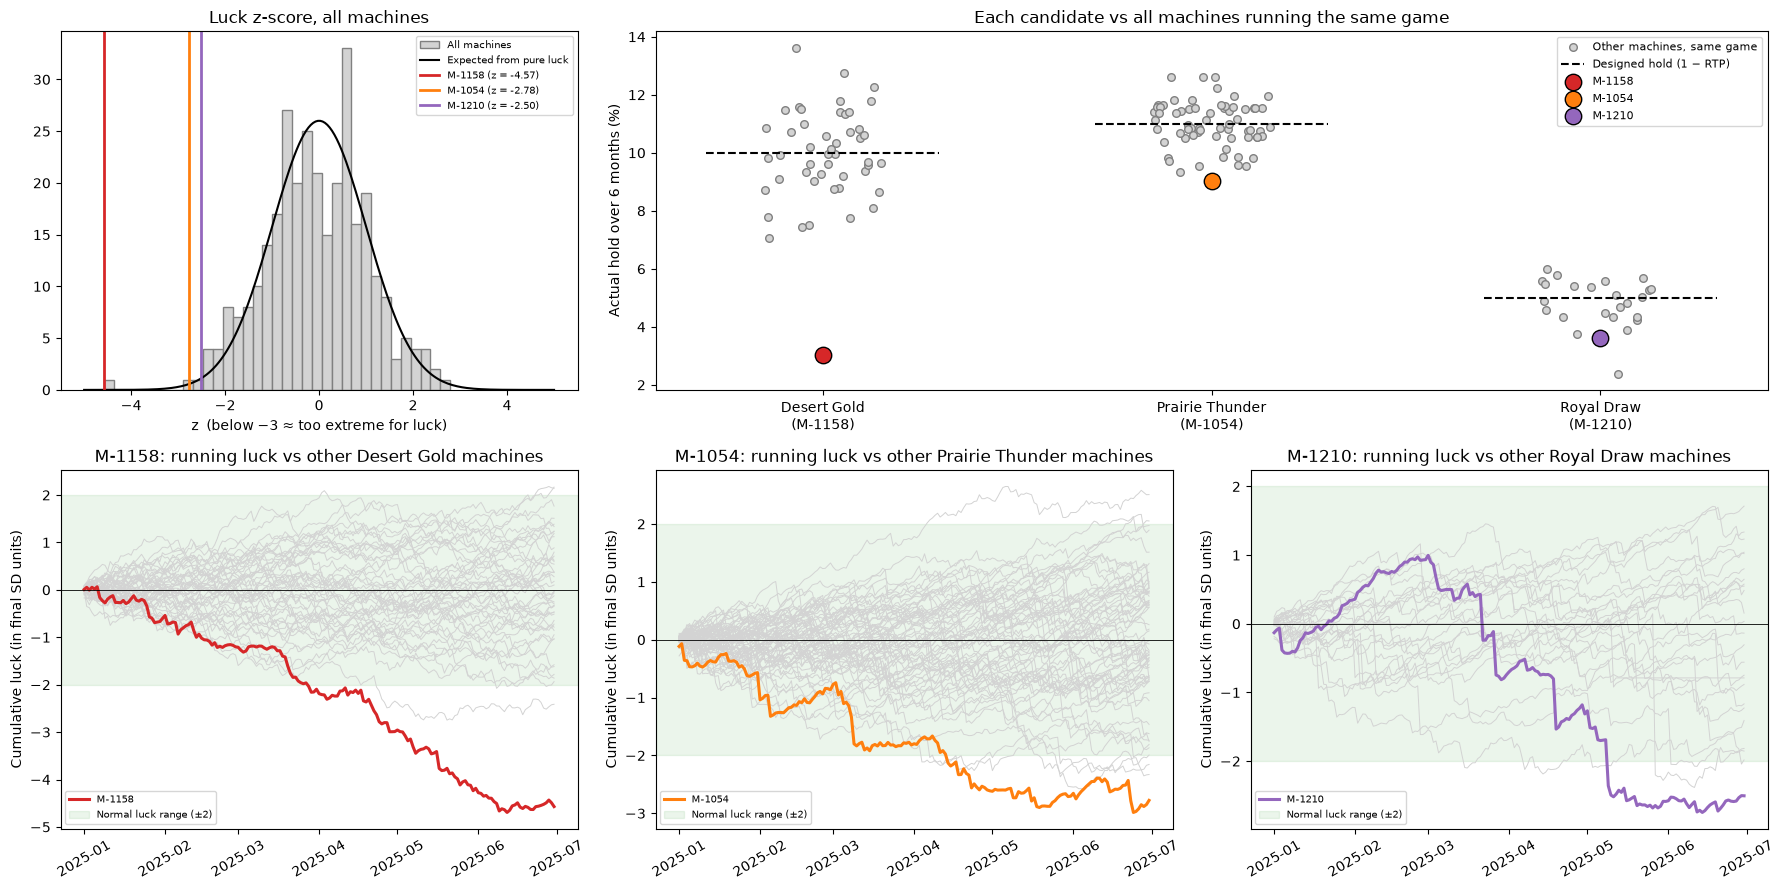

In [46]:
# Inspection candidates vs their peers: is each result too extreme to be luck?
from math import erf, sqrt
cands = {"M-1158": "tab:red", "M-1054": "tab:orange", "M-1210": "tab:purple"}

# Luck model inputs per machine and per day (same method as the luck test)
md = load("data/2_machine_decision/machine_day.parquet")
gm = load("data/2_machine_decision/game_math.parquet")
mdx = md[md["active"]].merge(gm[["config_id", "payout_multiplier_variance"]], on="config_id")
mdx["luck_var"] = mdx["sum_bet_squared"].astype(float) * mdx["payout_multiplier_variance"] / 1e4   # dollars²
dd = daily[daily["active"]].merge(mdx[["machine_id", "gaming_date", "luck_var"]], on=["machine_id", "gaming_date"])
dd["luck"] = dd["house_win_usd"] - dd["theo_usd"]

info = dd.groupby("machine_id").agg(theme=("theme", "first"), zone=("zone_name", "last"),
                                    coin=("coin_in_usd", "sum"), hw=("house_win_usd", "sum"), theo=("theo_usd", "sum"),
                                    luck=("luck", "sum"), var=("luck_var", "sum"))
info["z"] = info["luck"] / np.sqrt(info["var"])
info["actual_hold"] = info["hw"] / info["coin"]
info["designed_hold"] = info["theo"] / info["coin"]

# How many machines this extreme would we expect by pure chance among all machines?
n = len(info)
norm_cdf = lambda x: 0.5 * (1 + erf(x / sqrt(2)))
print(f"{'machine':8} {'game':16} {'zone':15} {'designed':>8} {'actual':>7} {'z':>6}  {'machines this low by chance (of ' + str(n) + ')':>36}  {'actually this low':>17}")
for mid in cands:
    r = info.loc[mid]
    expected = n * norm_cdf(r["z"])
    observed = (info["z"] <= r["z"]).sum()
    print(f"{mid:8} {r['theme']:16} {r['zone']:15} {r['designed_hold']:8.1%} {r['actual_hold']:7.1%} {r['z']:6.2f}  {expected:36.2f}  {observed:17d}")

fig = plt.figure(figsize=(18, 9))
grid = fig.add_gridspec(2, 3)

# 1) Distribution of luck z for all machines vs what pure luck predicts
ax = fig.add_subplot(grid[0, 0])
ax.hist(info["z"], bins=35, color="lightgray", edgecolor="gray", label="All machines")
xs = np.linspace(-5, 5, 200)
binw = (info["z"].max() - info["z"].min()) / 35
ax.plot(xs, n * binw * np.exp(-xs**2 / 2) / np.sqrt(2 * np.pi), color="black", label="Expected from pure luck")
for mid, col in cands.items():
    ax.axvline(info.loc[mid, "z"], color=col, linewidth=2, label=f"{mid} (z = {info.loc[mid, 'z']:.2f})")
ax.set_title("Luck z-score, all machines")
ax.set_xlabel("z  (below −3 ≈ too extreme for luck)")
ax.legend(fontsize=7)

# 2) Actual hold vs every other machine running the same game
ax = fig.add_subplot(grid[0, 1:])
games = [info.loc[m, "theme"] for m in cands]
for i, (g, mid) in enumerate(zip(games, cands)):
    peers = info[(info["theme"] == g) & (info.index != mid)]
    jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(peers))
    ax.scatter(i + jitter, peers["actual_hold"] * 100, color="lightgray", edgecolor="gray", s=30,
               label="Other machines, same game" if i == 0 else None)
    ax.hlines(peers["designed_hold"].iloc[0] * 100, i - 0.3, i + 0.3, color="black", linestyle="--",
              label="Designed hold (1 − RTP)" if i == 0 else None)
for i, (mid, col) in enumerate(cands.items()):
    ax.scatter(i, info.loc[mid, "actual_hold"] * 100, color=col, s=140, edgecolor="black", zorder=3, label=mid)
ax.set_xticks(range(len(games)), [f"{g}\n({m})" for g, m in zip(games, cands)])
ax.set_ylabel("Actual hold over 6 months (%)")
ax.set_title("Each candidate vs all machines running the same game")
ax.legend(fontsize=8, loc="upper right")

# 3) Running luck (in luck units) vs same-game peers, one panel per candidate
dd = dd.sort_values("gaming_date")
for i, (mid, col) in enumerate(cands.items()):
    ax = fig.add_subplot(grid[1, i])
    g = info.loc[mid, "theme"]
    sub = dd[dd["theme"] == g]
    cl = sub.pivot_table(index="gaming_date", columns="machine_id", values="luck", aggfunc="sum").fillna(0).cumsum()
    cv = sub.pivot_table(index="gaming_date", columns="machine_id", values="luck_var", aggfunc="sum").fillna(0).sum()
    cz = cl / np.sqrt(cv)
    ax.plot(cz.index, cz.drop(columns=mid), color="lightgray", linewidth=0.7)
    ax.plot(cz.index, cz[mid], color=col, linewidth=2.2, label=mid)
    ax.axhspan(-2, 2, color="green", alpha=0.08, label="Normal luck range (±2)")
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set_title(f"{mid}: running luck vs other {g} machines")
    ax.set_ylabel("Cumulative luck (in final SD units)")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(fontsize=7, loc="lower left")

plt.tight_layout()
plt.show()

### Q6 answer: fund 3 actions for $23,700 and keep $76,300

| Action | Cost | Expected July benefit (low – central – high) | Key assumption | How we'd measure it |
|---|---|---|---|---|
| **Inspect M-1158** | $1,200 (1-day lead) | $0 – $2.9K – $5.8K (about $73K/year if fixed) | 50% chance a fixable payout fault is found | Inspection finding; July actual hold vs designed 10% |
| **Signs for Back Forty** | $7,500 (10-day lead, 20 days of effect) | $0 – $14.8K – $29.6K | Closes 10% (central) to 20% (high) of Back Forty's gap; **break-even at +2.8% play** | Back Forty occupancy vs other zones (especially daytime, now 52–69% of floor); whole floor vs forecast to catch cannibalization |
| **One tournament-style promotion weekend, Jul 18–20** | $15,000 (14-day lead) | $34.6K – $60.6K – $86.5K | Summer lift 40–100% of the Winter Tournament's $86.5K net | Coin-in on Jul 18–20 above the forecast's **P90 line** (`model.ipynb`); lift in theo, comps and F&B vs normal same weekdays |
| **Keep** | $76,300 | — | — | — |

**Rejected:** replacing the bottom 10 or the 5 weak machines (a $3,380 lease recovers at most about $650 in July), moving machines (no empty slots in busy zones, so moves reshuffle play), an extra technician (all downtime ≈ $500/day; machines barely wait for repairs), Ridgeline preventive maintenance (about $3K benefit for $9K), and a floor-wide comp change (no evidence on player response).

**Next in line (August):** a **comp pilot with a control group ($4,000)** to test whether the May 1 halving of the comp price changes play. It costs about $28K a year in extra comps and doubled the value of unredeemed points. It was left out of July only because the guide allows 3 action types.

**Watch list (no spend):** M-1054 and M-1210. Recalculate their luck z after July and inspect only if it falls below −3.

**Responsible play:** the promotion is a broad property event, with no targeted invitations to heavy losers.

In [49]:
# The $100,000 menu: action costs from action_catalog, converted to dollars and July budget
catalog = load("data/2_machine_decision/action_catalog.parquet").set_index("action_type_id")

menu = pd.DataFrame({
    "action": catalog["name"],
    "unit_cost_$": catalog["unit_cost_cents"] / 100,
    "daily_cost_$": catalog["recurring_cost_cents_per_day"] / 100,
    "lead_days": catalog["lead_days"],
    "days_of_effect_in_july": (30 - catalog["lead_days"]).clip(lower=0),
    "downtime_min": catalog["downtime_minutes"],
    "max_qty": catalog["quantity_limit"],
    "conflicts_with": catalog["incompatibility_group"].fillna(""),
})

# Guide formula for one unit: unit cost + daily cost x max(0, 30 - lead days)
menu["july_cost_per_unit_$"] = menu["unit_cost_$"] + menu["daily_cost_$"] * menu["days_of_effect_in_july"]

pd.set_option("display.width", 250)
print(menu.to_string())
print("\nNotes from the catalog:")
for aid, note in catalog["notes"].items():
    print(f"  {aid:16} {note}")

                                                            action  unit_cost_$  daily_cost_$  lead_days  days_of_effect_in_july  downtime_min  max_qty conflicts_with  july_cost_per_unit_$
action_type_id                                                                                                                                                                              
A-MOVE-MACHINE                                Relocate one machine       1800.0           0.0          2                      28           180       24   same_machine                1800.0
A-MOVE-BANK                                  Relocate a whole bank       9500.0           0.0          5                      25           480        3   same_machine                9500.0
A-REPLACE-LEASE          Replace a machine with a leased new title       2500.0          55.0         14                      16           360       20   same_machine                3380.0
A-REPLACE-BUY         Replace a machine with a purchase

In [52]:
import pandas as pd
import plotly.graph_objects as go

daily = pd.read_parquet(
    "data/1_prepared_views/prepared_daily_view.parquet"
)

prop = pd.read_parquet(
    "data/1_prepared_views/property_day.parquet"
)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=prop["gaming_date"],
        y=prop["coin_in_usd"],
        mode="lines",
        name="Coin-In",
        line=dict(
            color="#00D8FF",
            width=3
        )
    )
)

fig.add_trace(
    go.Scatter(
        x=prop["gaming_date"],
        y=prop["theo_usd"] * 10,
        mode="lines",
        name="Theo × 10",
        line=dict(
            color="#EAA244",
            width=3
        )
    )
)

fig.update_layout(

    title="Whole Floor Performance",

    paper_bgcolor="#11244D",
    plot_bgcolor="#11244D",

    font=dict(
        color="white"
    ),

    xaxis_title="Date",

    yaxis_title="USD",

    hovermode="x unified",

    legend=dict(
        orientation="h",
        y=1.15,
        x=0
    )
)

fig.show()